<a href="https://colab.research.google.com/github/prattayabsmrstu/Wetland_Advance/blob/main/gopalganj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ============================================
# RESEARCH: GOPALGANJ WETLAND MAPPING
# NOTEBOOK 01: ENVIRONMENT SETUP
# ============================================

!pip -q install geopandas rasterio \
    matplotlib seaborn pandas numpy \
    pystac-client planetary-computer \
    shapely pyproj contextily requests \
    folium

print("All libraries installed successfully!")


All libraries installed successfully!


In [ ]:

# Import Libraries

import os
import json
import requests
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from shapely.geometry import shape
from pystac_client import Client
import planetary_computer as pc

warnings.filterwarnings("ignore")

# Visualization Settings
plt.rcParams["figure.figsize"] = (10, 8)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 11

sns.set_theme(style="whitegrid")

# Project Directory
PROJECT_DIR = "/content/Gopalganj_Wetland_Research"

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/Data", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/Figures", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/Results", exist_ok=True)

print("Environment setup completed.")
print("Project directory:", PROJECT_DIR)


Environment setup completed.
Project directory: /content/Gopalganj_Wetland_Research


In [ ]:

# ============================================
# GOPALGANJ DISTRICT BOUNDARY
# ============================================

import requests
import geopandas as gpd

API_URL = (
    "https://www.geoboundaries.org/api/current/"
    "gbOpen/BGD/ADM2/"
)

response = requests.get(API_URL, timeout=60)
response.raise_for_status()

boundary_info = response.json()

print("Available boundary metadata:")
print("Country:", boundary_info.get("boundaryISO"))
print("Administrative level:", boundary_info.get("boundaryType"))

geojson_url = boundary_info["gjDownloadURL"]

# Download administrative boundaries
all_districts = gpd.read_file(geojson_url)

print("\nAvailable columns:")
print(all_districts.columns.tolist())

print("\nSample district names:")
print(all_districts.head())


Available boundary metadata:
Country: BGD
Administrative level: ADM2

Available columns:
['shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType', 'geometry']

Sample district names:
   shapeName shapeISO                  shapeID shapeGroup shapeType  \
0   Bagerhat           16705992B77600989823530        BGD      ADM2   
1  Bandarban           16705992B23463827258150        BGD      ADM2   
2    Barguna           16705992B13795829103768        BGD      ADM2   
3    Barisal           16705992B66943755852345        BGD      ADM2   
4      Bhola           16705992B37732832620169        BGD      ADM2   

                                            geometry  
0  MULTIPOLYGON (((89.84021 21.82784, 89.84011 21...  
1  POLYGON ((92.61391 21.85191, 92.59671 21.86793...  
2  MULTIPOLYGON (((89.87968 22.07869, 89.88024 22...  
3  MULTIPOLYGON (((90.55435 22.59264, 90.55429 22...  
4  MULTIPOLYGON (((90.77172 21.85595, 90.77446 21...  


In [ ]:

# Find the district name column

name_candidates = [
    "shapeName",
    "NAME_2",
    "name",
    "NAME",
    "shapeName_1"
]

name_col = next(
    (col for col in name_candidates
     if col in all_districts.columns),
    None
)

if name_col is None:
    raise ValueError("District name column not found.")

# Select Gopalganj
gopalganj = all_districts[
    all_districts[name_col]
    .astype(str)
    .str.strip()
    .str.lower() == "gopalganj"
].copy()

if gopalganj.empty:
    print(all_districts[name_col].unique())
    raise ValueError("Gopalganj boundary not found.")

# Set CRS
if gopalganj.crs is None:
    raise ValueError("Boundary CRS is missing.")

# Reproject to WGS84
gopalganj = gopalganj.to_crs("EPSG:4326")

# Save boundary
boundary_path = (
    f"{PROJECT_DIR}/Data/"
    "Gopalganj_Boundary.geojson"
)

gopalganj.to_file(
    boundary_path,
    driver="GeoJSON"
)

print("Gopalganj boundary successfully extracted.")
print("Saved at:", boundary_path)
print("CRS:", gopalganj.crs)


Gopalganj boundary successfully extracted.
Saved at: /content/Gopalganj_Wetland_Research/Data/Gopalganj_Boundary.geojson
CRS: EPSG:4326


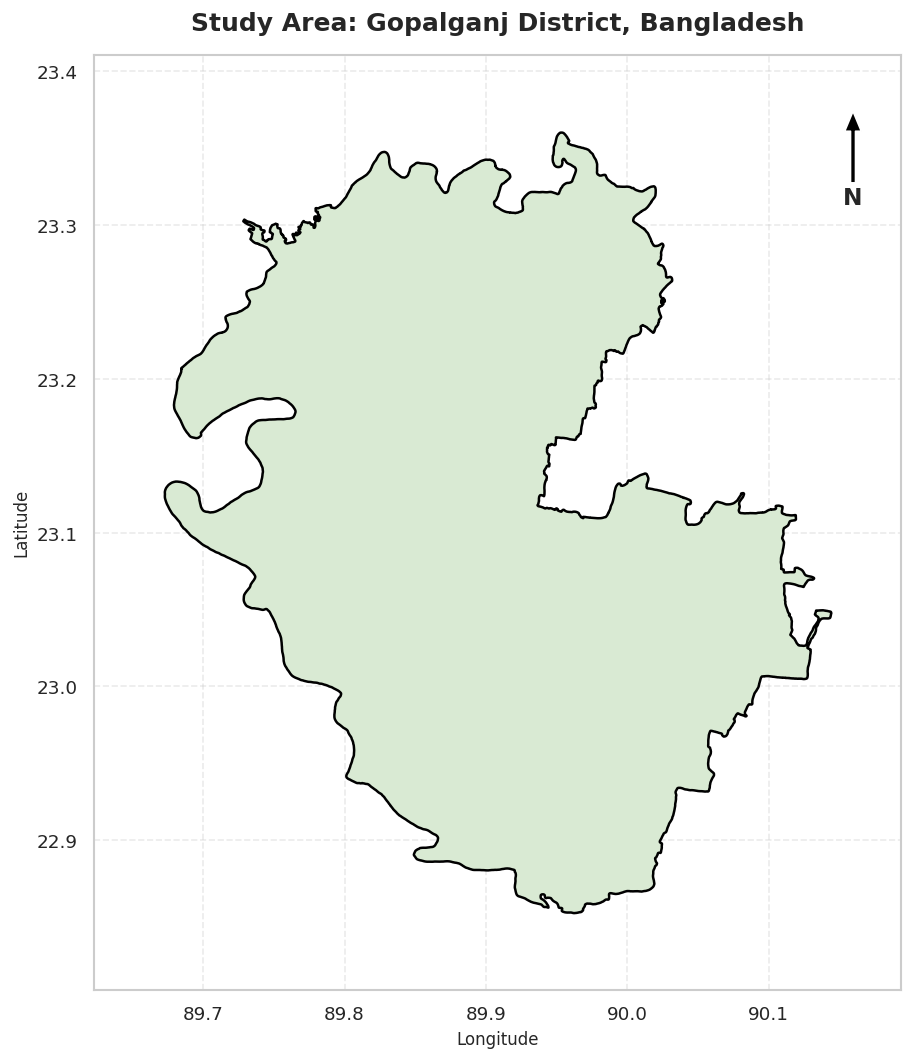

In [ ]:

# ============================================
# FIGURE 1: STUDY AREA LOCATION MAP
# ============================================

fig, ax = plt.subplots(figsize=(9, 9))

gopalganj.plot(
    ax=ax,
    facecolor="#d9ead3",
    edgecolor="black",
    linewidth=1.5
)

minx, miny, maxx, maxy = gopalganj.total_bounds

ax.set_xlim(minx - 0.05, maxx + 0.05)
ax.set_ylim(miny - 0.05, maxy + 0.05)

ax.set_title(
    "Study Area: Gopalganj District, Bangladesh",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# North Arrow
ax.annotate(
    "N",
    xy=(0.94, 0.94),
    xytext=(0.94, 0.84),
    xycoords="axes fraction",
    ha="center",
    fontsize=14,
    fontweight="bold",
    arrowprops=dict(
        facecolor="black",
        width=3,
        headwidth=10
    )
)

plt.tight_layout()

plt.savefig(
    f"{PROJECT_DIR}/Figures/Figure_01_Study_Area.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# ============================================
# STUDY AREA STATISTICS
# ============================================

# Gopalganj lies in UTM Zone 45N
gopalganj_utm = gopalganj.to_crs("EPSG:32645")

area_km2 = (
    gopalganj_utm.geometry.area.sum() / 1_000_000
)

bounds = gopalganj.total_bounds

study_stats = pd.DataFrame({
    "Parameter": [
        "District",
        "Country",
        "Area (km2)",
        "Minimum Longitude",
        "Maximum Longitude",
        "Minimum Latitude",
        "Maximum Latitude"
    ],
    "Value": [
        "Gopalganj",
        "Bangladesh",
        round(area_km2, 2),
        round(bounds[0], 5),
        round(bounds[2], 5),
        round(bounds[1], 5),
        round(bounds[3], 5)
    ]
})

display(study_stats)

study_stats.to_csv(
    f"{PROJECT_DIR}/Results/Study_Area_Statistics.csv",
    index=False
)


,Parameter,Value
0,District,Gopalganj
1,Country,Bangladesh
2,Area (km2),1477.97
3,Minimum Longitude,89.67257
4,Maximum Longitude,90.14377
5,Minimum Latitude,22.85293
6,Maximum Latitude,23.36054


In [ ]:

# ============================================
# SATELLITE DATA AVAILABILITY
# ============================================

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

# Study area geometry
study_geometry = gopalganj.geometry.union_all()
study_geojson = study_geometry.__geo_interface__

# Define seasons
seasons = {
    "Wet_2024": "2024-06-01/2024-09-30",
    "Dry_2024_25": "2024-12-01/2025-03-31"
}

collections = {
    "Sentinel_1": "sentinel-1-grd",
    "Sentinel_2": "sentinel-2-l2a"
}

search_results = []

for season_name, date_range in seasons.items():

    for sensor_name, collection_id in collections.items():

        print(
            f"Searching {sensor_name} | {season_name}"
        )

        search = catalog.search(
            collections=[collection_id],
            intersects=study_geojson,
            datetime=date_range,
            max_items=1000
        )

        items = list(search.items())

        search_results.append({
            "Season": season_name,
            "Sensor": sensor_name,
            "Collection": collection_id,
            "Date_Range": date_range,
            "Available_Scenes": len(items)
        })

        print("Scenes found:", len(items))

availability_df = pd.DataFrame(search_results)

display(availability_df)

availability_df.to_csv(
    f"{PROJECT_DIR}/Results/Satellite_Availability.csv",
    index=False
)


Searching Sentinel_1 | Wet_2024
Scenes found: 24
Searching Sentinel_2 | Wet_2024
Scenes found: 69
Searching Sentinel_1 | Dry_2024_25
Scenes found: 48
Searching Sentinel_2 | Dry_2024_25
Scenes found: 75


,Season,Sensor,Collection,Date_Range,Available_Scenes
0,Wet_2024,Sentinel_1,sentinel-1-grd,2024-06-01/2024-09-30,24
1,Wet_2024,Sentinel_2,sentinel-2-l2a,2024-06-01/2024-09-30,69
2,Dry_2024_25,Sentinel_1,sentinel-1-grd,2024-12-01/2025-03-31,48
3,Dry_2024_25,Sentinel_2,sentinel-2-l2a,2024-12-01/2025-03-31,75


In [ ]:

# ============================================
# NOTEBOOK 02 — DATA AVAILABILITY (2016–2026)
# Gopalganj, Bangladesh
# Sentinel-1 + Sentinel-2
# ============================================

!pip -q install pystac-client geopandas shapely pandas matplotlib seaborn tqdm

import os
import time
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from pystac_client import Client
from tqdm.auto import tqdm

# Google Drive / project folders
BASE_DIR = "/content/Gopalganj_Wetland_Research"
DATA_DIR = os.path.join(BASE_DIR, "Data")
RESULTS_DIR = os.path.join(BASE_DIR, "Results")
FIGURES_DIR = os.path.join(BASE_DIR, "Figures")

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    os.makedirs(folder, exist_ok=True)

# Load study area if not already loaded
if "gopalganj" not in globals():
    boundary_path = os.path.join(DATA_DIR, "Gopalganj_Boundary.geojson")
    gopalganj = gpd.read_file(boundary_path)

# Ensure WGS84
gopalganj = gopalganj.to_crs("EPSG:4326")
study_geometry = gopalganj.geometry.union_all()
study_geojson = gpd.GeoSeries(
    [study_geometry], crs="EPSG:4326"
).__geo_interface__["features"][0]["geometry"]

# Connect to Planetary Computer STAC
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

print("Study area and STAC connection ready.")
print("Study area bounds:", gopalganj.total_bounds)


Study area and STAC connection ready.
Study area bounds: [89.6725664  22.85292896 90.14377326 23.36054376]


In [ ]:

# ============================================
# SEARCH ALL SCENES: 2016–2026
# ============================================

COLLECTIONS = {
    "Sentinel_1": "sentinel-1-grd",
    "Sentinel_2": "sentinel-2-l2a"
}

records = []

# Wet season: June–September of each year
# Dry season: December–March (crosses calendar years)

tasks = []

for year in range(2016, 2027):

    tasks.append({
        "Season": f"Wet_{year}",
        "Season_Type": "Wet",
        "Season_Year": year,
        "Date_Range": f"{year}-06-01/{year}-09-30"
    })

    tasks.append({
        "Season": f"Dry_{year}_{year+1}",
        "Season_Type": "Dry",
        "Season_Year": year,
        "Date_Range": f"{year}-12-01/{year+1}-03-31"
    })

total_tasks = len(tasks) * len(COLLECTIONS)

with tqdm(total=total_tasks, desc="Searching satellite scenes") as pbar:

    for task in tasks:

        for sensor, collection_id in COLLECTIONS.items():

            try:
                search = catalog.search(
                    collections=[collection_id],
                    intersects=study_geojson,
                    datetime=task["Date_Range"]
                )

                # Count all matching STAC items
                scene_count = sum(1 for _ in search.items())

                records.append({
                    **task,
                    "Sensor": sensor,
                    "Collection": collection_id,
                    "Available_Scenes": scene_count,
                    "Status": "Success"
                })

            except Exception as e:

                print(
                    f"\nError: {sensor}, {task['Season']}: {e}"
                )

                records.append({
                    **task,
                    "Sensor": sensor,
                    "Collection": collection_id,
                    "Available_Scenes": None,
                    "Status": f"Error: {str(e)[:200]}"
                })

            pbar.update(1)

availability_df = pd.DataFrame(records)

availability_df = availability_df.sort_values(
    ["Season_Year", "Season_Type", "Sensor"]
).reset_index(drop=True)

# Save detailed results
csv_path = os.path.join(
    RESULTS_DIR, "Satellite_Availability_2016_2026.csv"
)

availability_df.to_csv(csv_path, index=False)

print("\nDATA AVAILABILITY SUMMARY")
display(availability_df)

print("\nSaved:", csv_path)


Searching satellite scenes:   0%|          | 0/44 [00:00<?, ?it/s]


DATA AVAILABILITY SUMMARY


,Season,Season_Type,Season_Year,Date_Range,Sensor,Collection,Available_Scenes,Status
0,Dry_2016_2017,Dry,2016,2016-12-01/2017-03-31,Sentinel_1,sentinel-1-grd,24,Success
1,Dry_2016_2017,Dry,2016,2016-12-01/2017-03-31,Sentinel_2,sentinel-2-l2a,20,Success
2,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,12,Success
3,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_2,sentinel-2-l2a,20,Success
4,Dry_2017_2018,Dry,2017,2017-12-01/2018-03-31,Sentinel_1,sentinel-1-grd,29,Success
5,Dry_2017_2018,Dry,2017,2017-12-01/2018-03-31,Sentinel_2,sentinel-2-l2a,60,Success
6,Wet_2017,Wet,2017,2017-06-01/2017-09-30,Sentinel_1,sentinel-1-grd,24,Success
7,Wet_2017,Wet,2017,2017-06-01/2017-09-30,Sentinel_2,sentinel-2-l2a,30,Success
8,Dry_2018_2019,Dry,2018,2018-12-01/2019-03-31,Sentinel_1,sentinel-1-grd,27,Success
9,Dry_2018_2019,Dry,2018,2018-12-01/2019-03-31,Sentinel_2,sentinel-2-l2a,72,Success



Saved: /content/Gopalganj_Wetland_Research/Results/Satellite_Availability_2016_2026.csv


Sensor,Season_Year,Sentinel_1,Sentinel_2
0,2016,36,40
1,2017,53,90
2,2018,53,147
3,2019,54,147
4,2020,59,143
5,2021,57,176
6,2022,59,199
7,2023,47,217
8,2024,72,144
9,2025,71,178


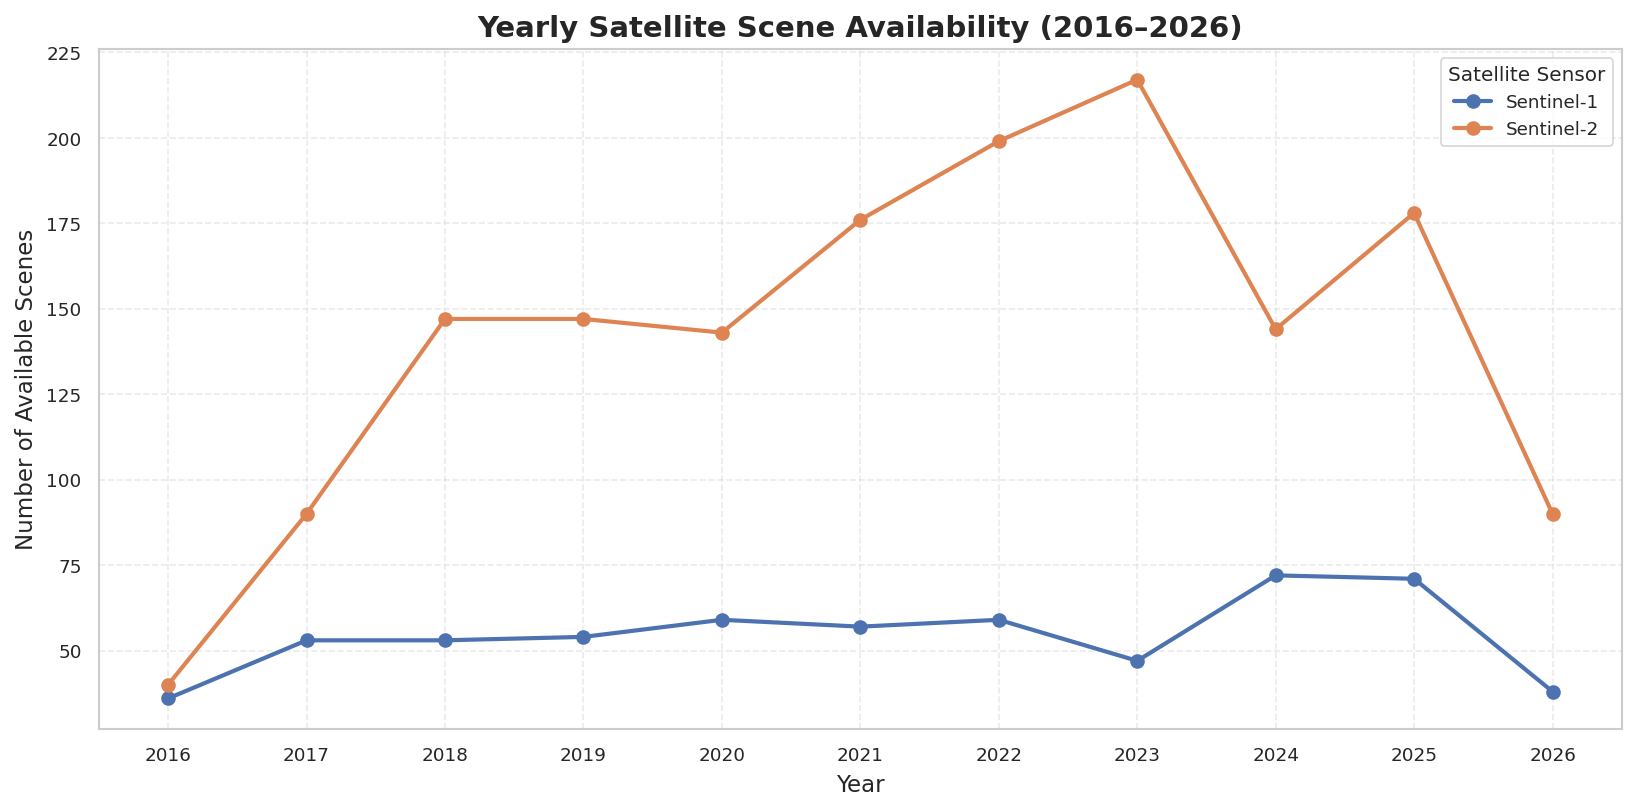

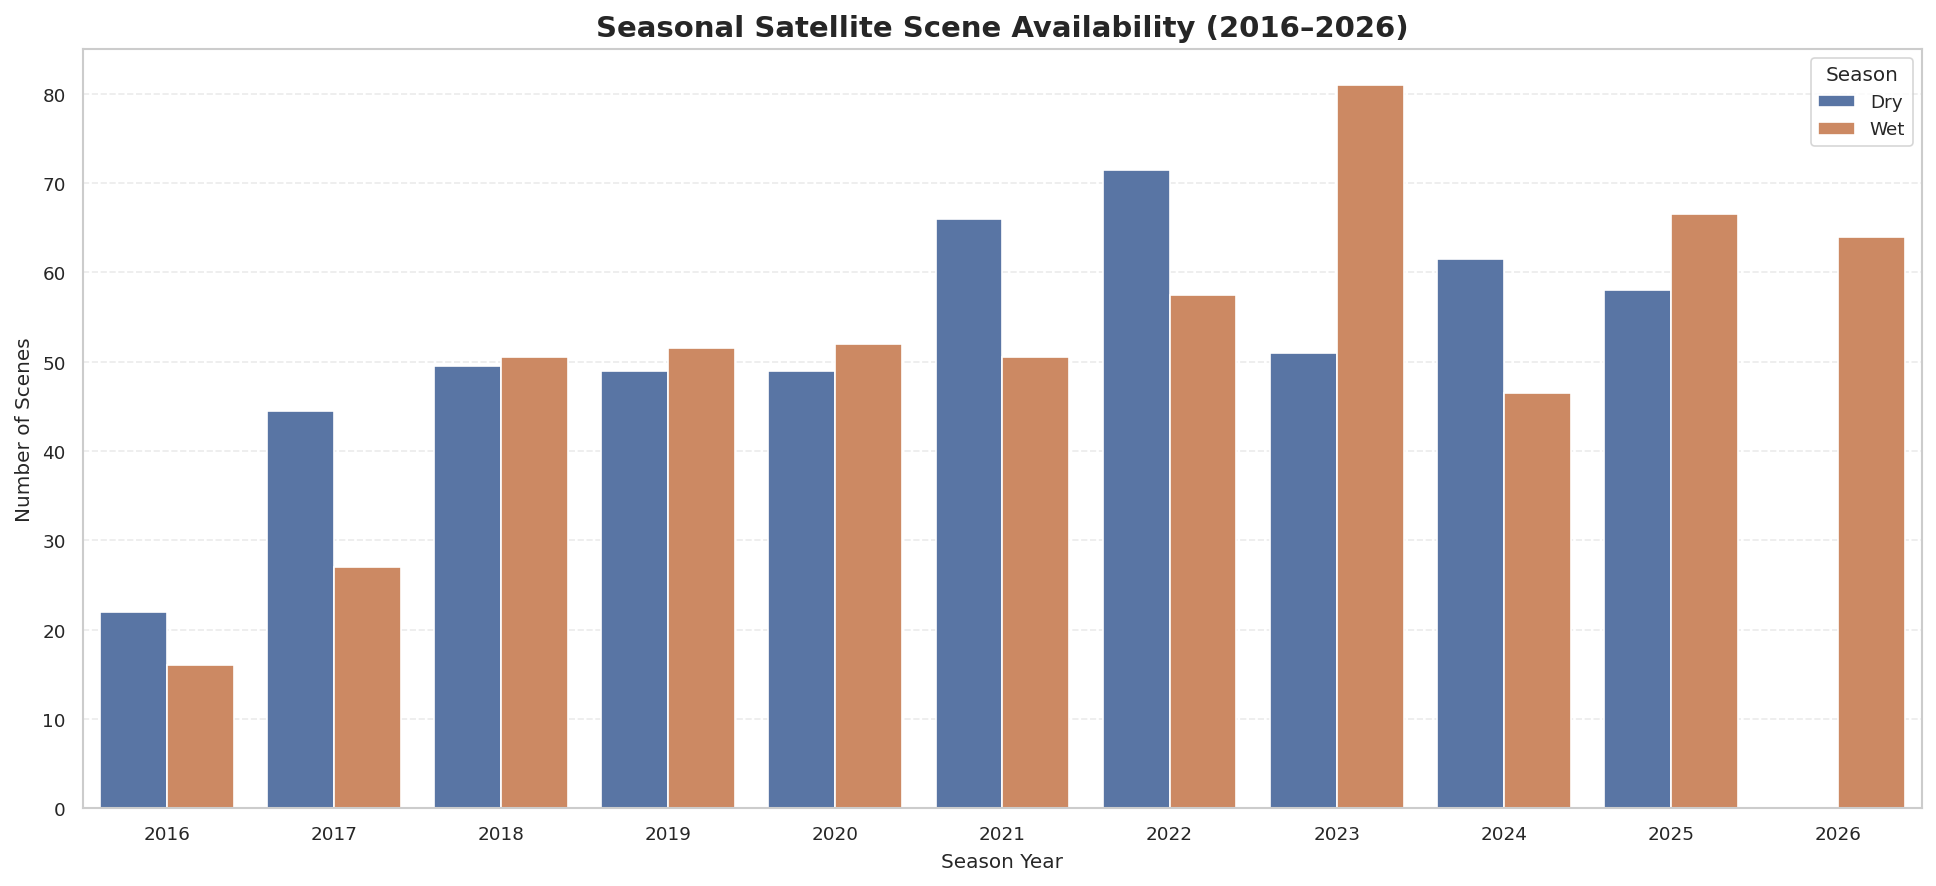

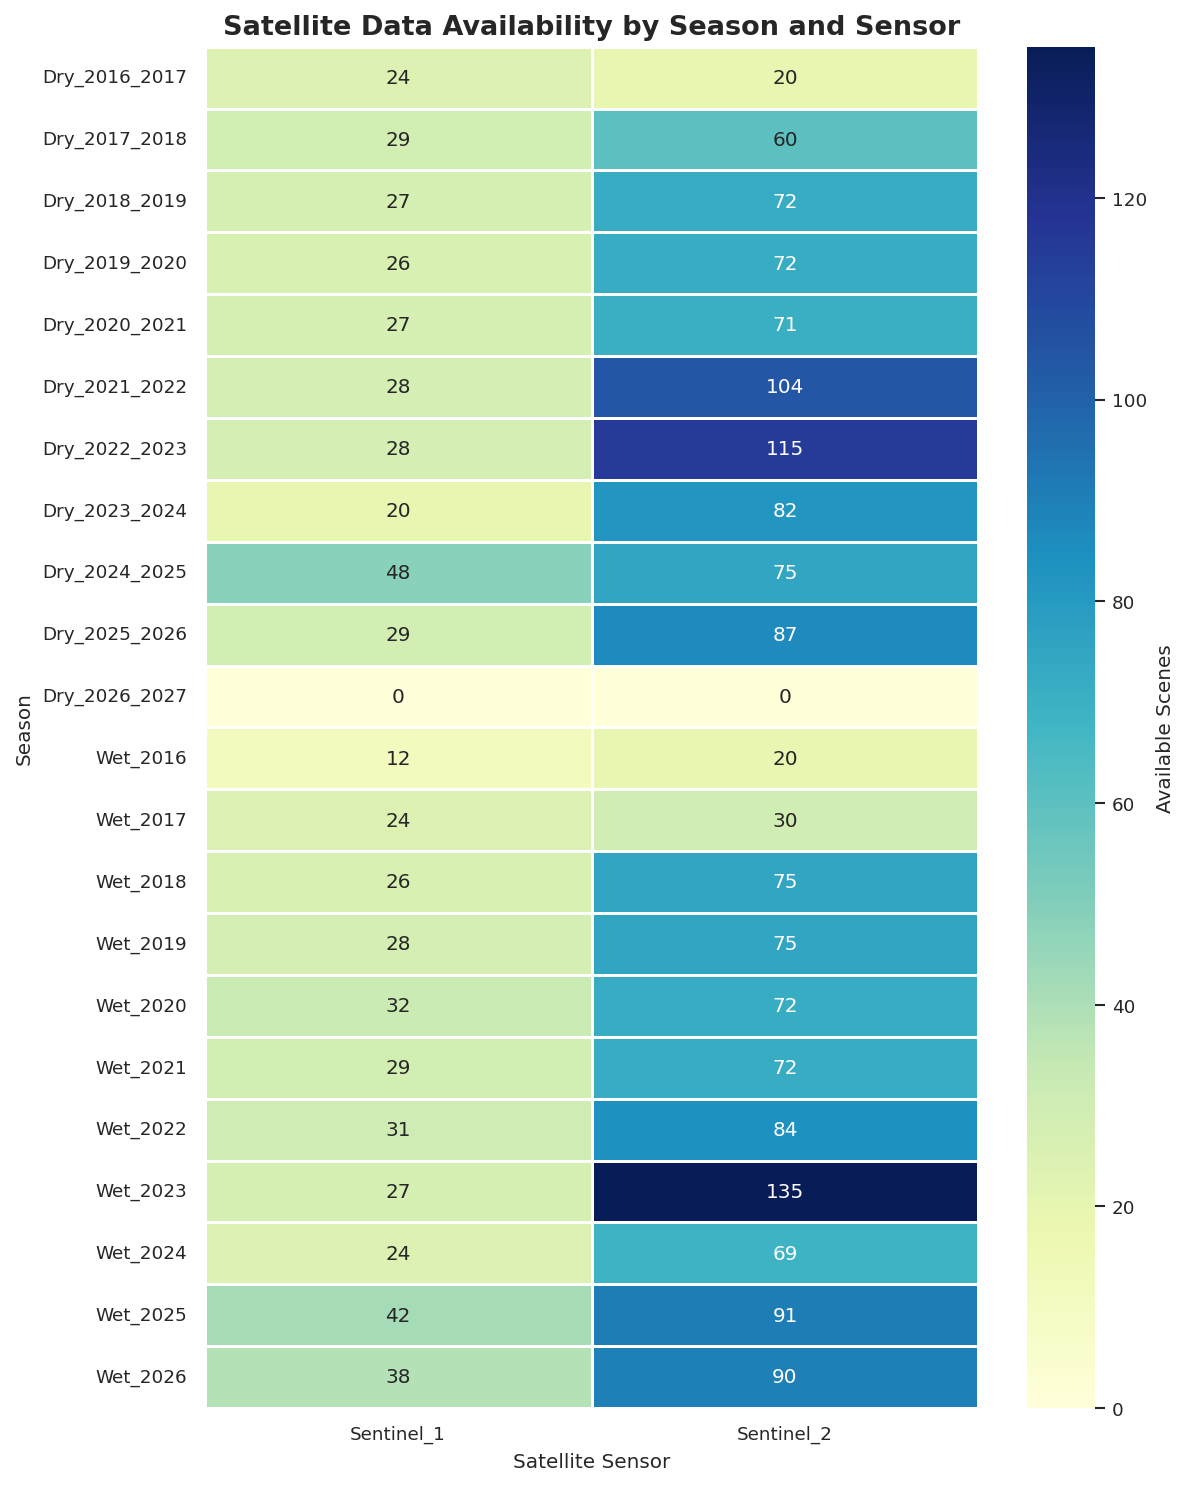


All figures and CSV files saved successfully.
Figures folder: /content/Gopalganj_Wetland_Research/Figures
Results folder: /content/Gopalganj_Wetland_Research/Results


In [ ]:

# ============================================
# YEARLY SUMMARY
# ============================================

successful = availability_df[
    availability_df["Status"] == "Success"
].copy()

successful["Available_Scenes"] = pd.to_numeric(
    successful["Available_Scenes"], errors="coerce"
)

# Total scenes by year and sensor
yearly_summary = (
    successful.groupby(["Season_Year", "Sensor"])
    ["Available_Scenes"].sum()
    .unstack(fill_value=0)
    .reset_index()
)

display(yearly_summary)

yearly_summary.to_csv(
    os.path.join(RESULTS_DIR, "Yearly_Scene_Summary.csv"),
    index=False
)

# Publication style
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.family"] = "DejaVu Sans"

# ============================================
# FIGURE 1: YEARLY SENSOR AVAILABILITY
# ============================================

fig, ax = plt.subplots(figsize=(11, 5.5))

for sensor in ["Sentinel_1", "Sentinel_2"]:
    if sensor in yearly_summary.columns:
        ax.plot(
            yearly_summary["Season_Year"],
            yearly_summary[sensor],
            marker="o",
            linewidth=2,
            markersize=6,
            label=sensor.replace("_", "-")
        )

ax.set_title(
    "Yearly Satellite Scene Availability (2016–2026)",
    fontsize=14, fontweight="bold"
)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Number of Available Scenes", fontsize=11)
ax.set_xticks(range(2016, 2027))
ax.legend(title="Satellite Sensor")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "Figure_03_Yearly_Availability.png"),
    bbox_inches="tight"
)
plt.show()


# ============================================
# FIGURE 2: WET vs DRY SEASON
# ============================================

season_summary = (
    successful.groupby(["Season_Year", "Season_Type", "Sensor"])
    ["Available_Scenes"].sum()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(13, 6))

sns.barplot(
    data=season_summary,
    x="Season_Year",
    y="Available_Scenes",
    hue="Season_Type",
    ax=ax,
    errorbar=None
)

ax.set_title(
    "Seasonal Satellite Scene Availability (2016–2026)",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Season Year")
ax.set_ylabel("Number of Scenes")
ax.legend(title="Season")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "Figure_04_Seasonal_Availability.png"),
    bbox_inches="tight"
)
plt.show()


# ============================================
# FIGURE 3: AVAILABILITY HEATMAP
# ============================================

heatmap_data = successful.pivot_table(
    index="Season",
    columns="Sensor",
    values="Available_Scenes",
    aggfunc="sum"
)

fig, ax = plt.subplots(figsize=(8, 10))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Available Scenes"},
    ax=ax
)

ax.set_title(
    "Satellite Data Availability by Season and Sensor",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Satellite Sensor")
ax.set_ylabel("Season")

plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "Figure_05_Availability_Heatmap.png"),
    bbox_inches="tight"
)
plt.show()


print("\nAll figures and CSV files saved successfully.")
print("Figures folder:", FIGURES_DIR)
print("Results folder:", RESULTS_DIR)


Season_Type        Dry                   Wet           
Sensor      Sentinel_1 Sentinel_2 Sentinel_1 Sentinel_2
Season_Year                                            
2016                24         20         12         20
2017                29         60         24         30
2018                27         72         26         75
2019                26         72         28         75
2020                27         71         32         72
2021                28        104         29         72
2022                28        115         31         84
2023                20         82         27        135
2024                48         75         24         69
2025                29         87         42         91
2026                 0          0         38         90

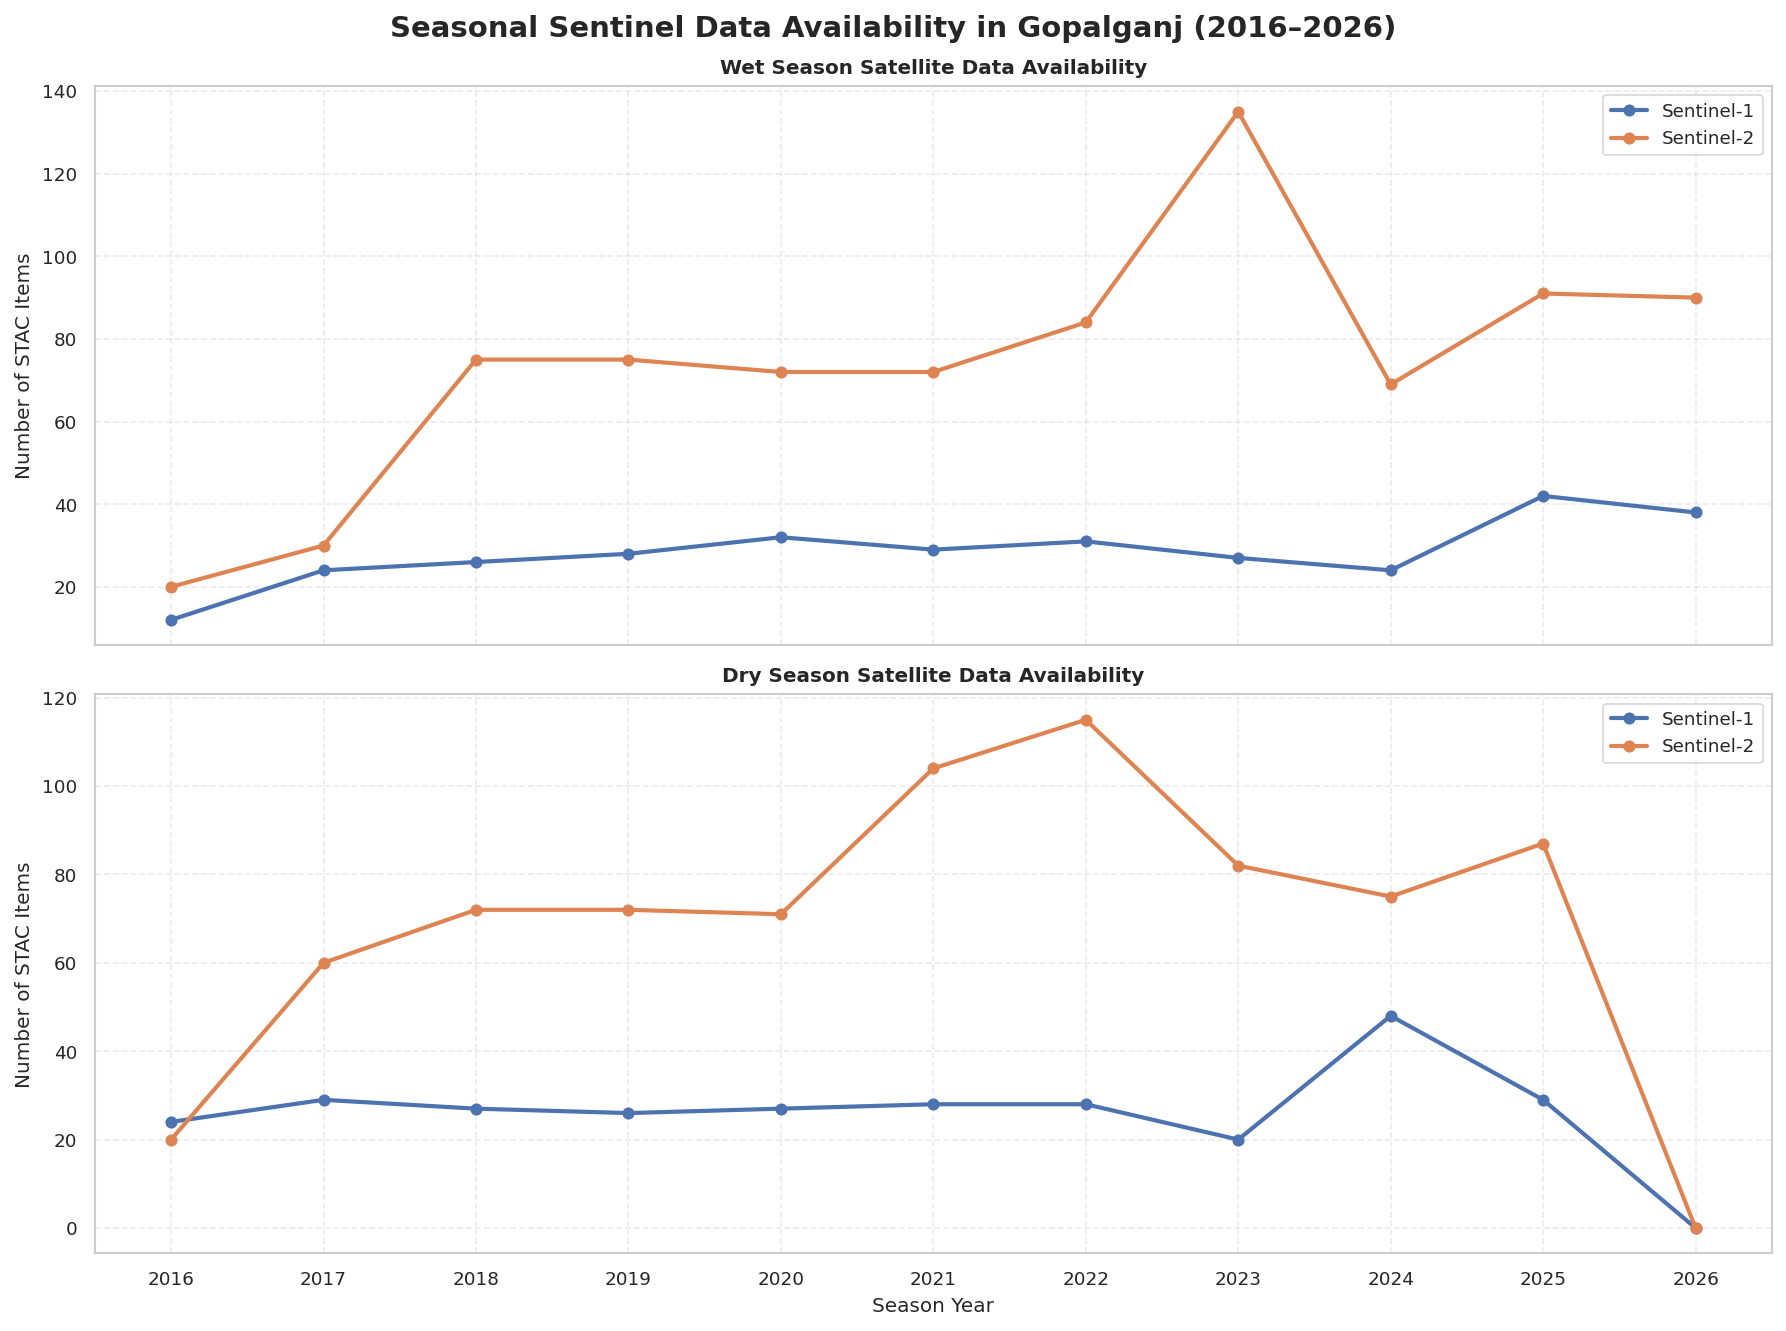

In [ ]:

# ============================================
# SEASON-WISE DATA AVAILABILITY ANALYSIS
# ============================================

# Separate wet and dry season counts
season_pivot = successful.pivot_table(
    index="Season_Year",
    columns=["Season_Type", "Sensor"],
    values="Available_Scenes",
    aggfunc="sum",
    fill_value=0
)

display(season_pivot)

season_pivot.to_csv(
    os.path.join(
        RESULTS_DIR,
        "Wet_Dry_Season_Availability_2016_2026.csv"
    )
)

# ============================================
# TWO-PANEL PUBLICATION GRAPH
# ============================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    sharex=True
)

for ax, season_type in zip(axes, ["Wet", "Dry"]):

    subset = successful[
        successful["Season_Type"] == season_type
    ]

    for sensor in ["Sentinel_1", "Sentinel_2"]:

        sensor_data = subset[
            subset["Sensor"] == sensor
        ].sort_values("Season_Year")

        ax.plot(
            sensor_data["Season_Year"],
            sensor_data["Available_Scenes"],
            marker="o",
            linewidth=2,
            label=sensor.replace("_", "-")
        )

    ax.set_title(
        f"{season_type} Season Satellite Data Availability",
        fontweight="bold"
    )
    ax.set_ylabel("Number of STAC Items")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.4)

axes[-1].set_xlabel("Season Year")
axes[-1].set_xticks(range(2016, 2027))

plt.suptitle(
    "Seasonal Sentinel Data Availability in Gopalganj (2016–2026)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "Figure_06_Wet_Dry_Sensor_Availability.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# ============================================
# SCENE-LEVEL METADATA EXTRACTION
# 2016–2026 | Sentinel-1 and Sentinel-2
# ============================================

import pandas as pd
import os
from tqdm.auto import tqdm

scene_records = []

for task in tqdm(tasks, desc="Collecting scene metadata"):

    for sensor, collection_id in COLLECTIONS.items():

        try:
            search = catalog.search(
                collections=[collection_id],
                intersects=study_geojson,
                datetime=task["Date_Range"]
            )

            items = search.items()

            for item in items:

                props = item.properties

                # Common metadata
                record = {
                    "Season": task["Season"],
                    "Season_Type": task["Season_Type"],
                    "Season_Year": task["Season_Year"],
                    "Date_Range": task["Date_Range"],
                    "Sensor": sensor,
                    "Collection": collection_id,
                    "Scene_ID": item.id,
                    "Acquisition_Date": (
                        item.datetime.date()
                        if item.datetime else None
                    ),
                    "Platform": props.get("platform"),
                    "Cloud_Cover_Percent": props.get(
                        "eo:cloud_cover"
                    ),
                    "Orbit_State": props.get("sat:orbit_state"),
                    "Relative_Orbit": props.get(
                        "sat:relative_orbit"
                    ),
                }

                # Sentinel-1 specific metadata
                if sensor == "Sentinel_1":

                    record["Polarizations"] = str(
                        props.get("sar:polarizations")
                    )

                    record["Instrument_Mode"] = props.get(
                        "sar:instrument_mode"
                    )

                    record["Product_Type"] = props.get(
                        "sar:product_type"
                    )

                else:

                    record["Polarizations"] = None
                    record["Instrument_Mode"] = None
                    record["Product_Type"] = None

                scene_records.append(record)

        except Exception as e:
            print(
                f"Metadata error: {task['Season']} "
                f"{sensor}: {e}"
            )

scene_df = pd.DataFrame(scene_records)

# Save full scene-level metadata
metadata_path = os.path.join(
    RESULTS_DIR,
    "Scene_Metadata_2016_2026.csv"
)

scene_df.to_csv(metadata_path, index=False)

print("Total scene records:", len(scene_df))
print("Saved:", metadata_path)

display(scene_df.head(10))


Total scene records: 2170
Saved: /content/Gopalganj_Wetland_Research/Results/Scene_Metadata_2016_2026.csv


,Season,Season_Type,Season_Year,Date_Range,Sensor,Collection,Scene_ID,Acquisition_Date,Platform,Cloud_Cover_Percent,Orbit_State,Relative_Orbit,Polarizations,Instrument_Mode,Product_Type
0,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SSV_20160920T120421_20160920T1204...,2016-09-20,SENTINEL-1A,NaN,ascending,114,['VV'],IW,GRD
1,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SSV_20160920T120352_20160920T1204...,2016-09-20,SENTINEL-1A,NaN,ascending,114,['VV'],IW,GRD
2,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SDV_20160910T235557_20160910T2356...,2016-09-10,SENTINEL-1A,NaN,descending,150,"['VV', 'VH']",IW,GRD
3,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SSV_20160827T120420_20160827T1204...,2016-08-27,SENTINEL-1A,NaN,ascending,114,['VV'],IW,GRD
4,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SSV_20160827T120351_20160827T1204...,2016-08-27,SENTINEL-1A,NaN,ascending,114,['VV'],IW,GRD
5,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SDV_20160817T235556_20160817T2356...,2016-08-17,SENTINEL-1A,NaN,descending,150,"['VV', 'VH']",IW,GRD
6,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SSV_20160803T120419_20160803T1204...,2016-08-03,SENTINEL-1A,NaN,ascending,114,['VV'],IW,GRD
7,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SSV_20160803T120350_20160803T1204...,2016-08-03,SENTINEL-1A,NaN,ascending,114,['VV'],IW,GRD
8,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SDV_20160724T235554_20160724T2356...,2016-07-24,SENTINEL-1A,NaN,descending,150,"['VV', 'VH']",IW,GRD
9,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SDV_20160630T235553_20160630T2356...,2016-06-30,SENTINEL-1A,NaN,descending,150,"['VV', 'VH']",IW,GRD


,Season_Year,Season_Type,count,mean,median,min,max
0,2016,Dry,20,0.94,0.31,0.01,8.71
1,2016,Wet,20,65.24,59.49,24.18,100.00
2,2017,Dry,60,33.24,18.06,0.01,100.00
3,2017,Wet,30,82.40,90.75,13.97,100.00
4,2018,Dry,72,21.69,0.09,0.01,99.91
5,2018,Wet,75,71.30,75.71,20.26,100.00
6,2019,Dry,72,29.69,3.25,0.01,100.00
7,2019,Wet,75,70.99,79.71,11.01,100.00
8,2020,Dry,71,17.58,0.16,0.01,100.00
9,2020,Wet,72,73.69,79.92,25.98,100.00


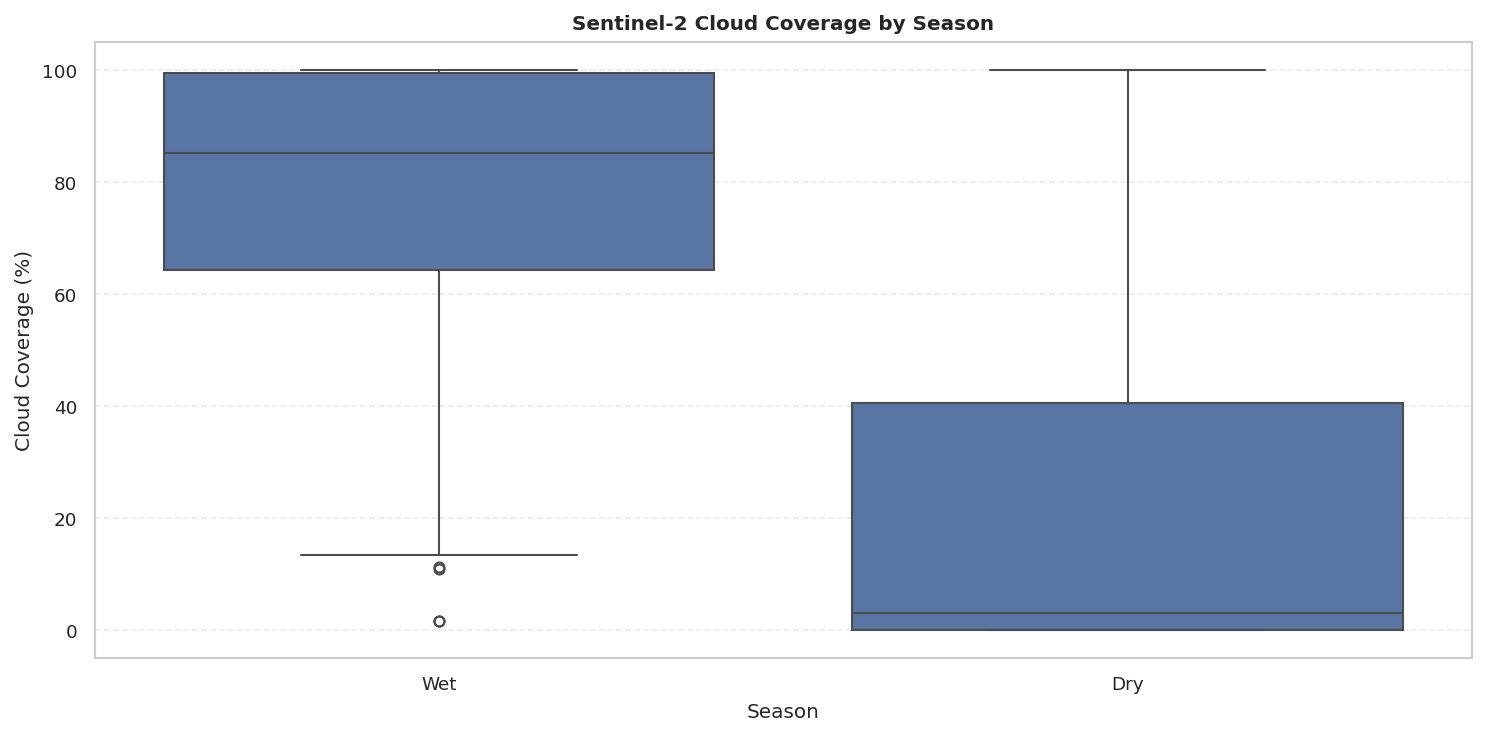

In [ ]:

# ============================================
# SENTINEL-2 CLOUD COVERAGE
# ============================================

s2_df = scene_df[
    scene_df["Sensor"] == "Sentinel_2"
].copy()

s2_df["Cloud_Cover_Percent"] = pd.to_numeric(
    s2_df["Cloud_Cover_Percent"],
    errors="coerce"
)

cloud_summary = (
    s2_df.groupby(["Season_Year", "Season_Type"])
    ["Cloud_Cover_Percent"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

display(cloud_summary.round(2))

cloud_summary.to_csv(
    os.path.join(
        RESULTS_DIR,
        "Sentinel2_Cloud_Summary.csv"
    ),
    index=False
)

# Cloud coverage distribution
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=s2_df,
    x="Season_Type",
    y="Cloud_Cover_Percent"
)

plt.title(
    "Sentinel-2 Cloud Coverage by Season",
    fontweight="bold"
)
plt.xlabel("Season")
plt.ylabel("Cloud Coverage (%)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "Figure_07_Sentinel2_Cloud_Coverage.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# ============================================
# PRELIMINARY USABLE SCENE SCREENING
# ============================================

# Sentinel-2: cloud cover <= 30%
s2_usable = s2_df[
    s2_df["Cloud_Cover_Percent"].notna()
    & (s2_df["Cloud_Cover_Percent"] <= 30)
].copy()

# Sentinel-1: require VV and VH polarization
s1_df = scene_df[
    scene_df["Sensor"] == "Sentinel_1"
].copy()

def has_vv_vh(value):
    value = str(value).upper()
    return "VV" in value and "VH" in value

s1_usable = s1_df[
    s1_df["Polarizations"].apply(has_vv_vh)
].copy()

# Summary
usable_summary = pd.concat([
    s2_usable.assign(Usable_Status="S2 Cloud <= 30%"),
    s1_usable.assign(Usable_Status="S1 VV + VH")
])

usable_counts = (
    usable_summary.groupby(
        ["Season_Year", "Season_Type", "Sensor"]
    )
    .size()
    .reset_index(name="Preliminary_Usable_Scenes")
)

display(usable_counts)

usable_counts.to_csv(
    os.path.join(
        RESULTS_DIR,
        "Preliminary_Usable_Scene_Counts.csv"
    ),
    index=False
)

print("Sentinel-2 scenes with cloud <= 30%:", len(s2_usable))
print("Sentinel-1 scenes with VV and VH:", len(s1_usable))


,Season_Year,Season_Type,Sensor,Preliminary_Usable_Scenes
0,2016,Dry,Sentinel_1,16
1,2016,Dry,Sentinel_2,20
2,2016,Wet,Sentinel_1,6
3,2016,Wet,Sentinel_2,2
4,2017,Dry,Sentinel_1,29
5,2017,Dry,Sentinel_2,31
6,2017,Wet,Sentinel_1,24
7,2017,Wet,Sentinel_2,1
8,2018,Dry,Sentinel_1,27
9,2018,Dry,Sentinel_2,54


Sentinel-2 scenes with cloud <= 30%: 562
Sentinel-1 scenes with VV and VH: 585


In [ ]:

# ============================================
# VERIFY SENTINEL-1 USABLE SCENE COUNTS
# ============================================

print("Total Sentinel-1 metadata records:", len(s1_df))
print("Total Sentinel-1 VV+VH records:", len(s1_usable))

print("\nPolarization distribution:")
display(
    s1_df["Polarizations"]
    .value_counts(dropna=False)
)

print("\nSeason-wise Sentinel-1 usable count:")

s1_check = (
    s1_usable.groupby(
        ["Season_Year", "Season_Type"],
        dropna=False
    )
    .size()
    .reset_index(name="VV_VH_Scenes")
)

display(s1_check)

print(
    "\nSum of grouped Sentinel-1 records:",
    s1_check["VV_VH_Scenes"].sum()
)

print(
    "\nUnassigned season/year records:",
    s1_usable[
        s1_usable["Season_Year"].isna()
        | s1_usable["Season_Type"].isna()
    ].shape[0]
)


Total Sentinel-1 metadata records: 599
Total Sentinel-1 VV+VH records: 585

Polarization distribution:


,count
Polarizations,
"['VV', 'VH']",585
['VV'],14



Season-wise Sentinel-1 usable count:


,Season_Year,Season_Type,VV_VH_Scenes
0,2016,Dry,16
1,2016,Wet,6
2,2017,Dry,29
3,2017,Wet,24
4,2018,Dry,27
5,2018,Wet,26
6,2019,Dry,26
7,2019,Wet,28
8,2020,Dry,27
9,2020,Wet,32



Sum of grouped Sentinel-1 records: 585

Unassigned season/year records: 0


In [ ]:

# Step 9.1: Sentinel-1 preprocessing setup

!pip -q install pystac-client planetary-computer stackstac rioxarray rasterio geopandas

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import pystac_client
import planetary_computer
import stackstac
import rasterio
import rioxarray

from IPython.display import display

# Project directory
PROJECT_DIR = "/content/Gopalganj_Wetland_Research"
DATA_DIR = os.path.join(PROJECT_DIR, "Data")
RESULTS_DIR = os.path.join(PROJECT_DIR, "Results")

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Connect to Microsoft Planetary Computer
STAC_URL = "https://planetarycomputer.microsoft.com/api/stac/v1"

catalog = pystac_client.Client.open(
    STAC_URL,
    modifier=planetary_computer.sign_inplace
)

print("Planetary Computer connection: successful")
print("Project directory:", PROJECT_DIR)

# Check existing Sentinel-1 DataFrame
if "s1_usable" in globals():
    print("\nUsing s1_usable DataFrame")
    print("Total VV+VH records:", len(s1_usable))
    print("Available columns:")
    print(s1_usable.columns.tolist())
    display(s1_usable.head(5))

elif "scene_df" in globals():
    print("\nUsing scene_df DataFrame")
    print("Total metadata records:", len(scene_df))
    print("Available columns:")
    print(scene_df.columns.tolist())
    display(scene_df.head(5))

else:
    print("ERROR: Sentinel-1 DataFrame not found.")
    print("Please run the previous scene metadata cells first.")


Planetary Computer connection: successful
Project directory: /content/Gopalganj_Wetland_Research

Using s1_usable DataFrame
Total VV+VH records: 585
Available columns:
['Season', 'Season_Type', 'Season_Year', 'Date_Range', 'Sensor', 'Collection', 'Scene_ID', 'Acquisition_Date', 'Platform', 'Cloud_Cover_Percent', 'Orbit_State', 'Relative_Orbit', 'Polarizations', 'Instrument_Mode', 'Product_Type']


,Season,Season_Type,Season_Year,Date_Range,Sensor,Collection,Scene_ID,Acquisition_Date,Platform,Cloud_Cover_Percent,Orbit_State,Relative_Orbit,Polarizations,Instrument_Mode,Product_Type
2,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SDV_20160910T235557_20160910T2356...,2016-09-10,SENTINEL-1A,NaN,descending,150,"['VV', 'VH']",IW,GRD
5,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SDV_20160817T235556_20160817T2356...,2016-08-17,SENTINEL-1A,NaN,descending,150,"['VV', 'VH']",IW,GRD
8,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SDV_20160724T235554_20160724T2356...,2016-07-24,SENTINEL-1A,NaN,descending,150,"['VV', 'VH']",IW,GRD
9,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SDV_20160630T235553_20160630T2356...,2016-06-30,SENTINEL-1A,NaN,descending,150,"['VV', 'VH']",IW,GRD
10,Wet_2016,Wet,2016,2016-06-01/2016-09-30,Sentinel_1,sentinel-1-grd,S1A_IW_GRDH_1SDV_20160606T235552_20160606T2356...,2016-06-06,SENTINEL-1A,NaN,descending,150,"['VV', 'VH']",IW,GRD


In [ ]:

# Step 9.2: Inspect one Sentinel-1 GRD scene

import pystac_client
import planetary_computer
import rasterio
from rasterio.windows import Window

# Select one representative scene
sample_row = s1_usable.iloc[0]

scene_id = sample_row["Scene_ID"]
collection_id = sample_row["Collection"]

print("Selected Scene ID:")
print(scene_id)

print("\nAcquisition date:", sample_row["Acquisition_Date"])
print("Orbit:", sample_row["Orbit_State"])
print("Relative orbit:", sample_row["Relative_Orbit"])

# Retrieve the scene from STAC
search = catalog.search(
    collections=[collection_id],
    ids=[scene_id]
)

items = list(search.items())

print("\nNumber of matched STAC items:", len(items))

if len(items) == 0:
    raise ValueError("Scene not found in Planetary Computer STAC catalog.")

item = items[0]

print("\nAvailable assets:")
for asset_key, asset in item.assets.items():
    print(asset_key, "->", asset.media_type)

# Inspect VV and VH assets
for polarization in ["vv", "vh"]:

    if polarization not in item.assets:
        print(f"\n{polarization.upper()} asset not found!")
        continue

    asset_href = item.assets[polarization].href

    print(f"\n{polarization.upper()} Raster Information:")

    with rasterio.open(asset_href) as src:

        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Width:", src.width)
        print("Height:", src.height)
        print("Band count:", src.count)
        print("Data type:", src.dtypes)
        print("NoData:", src.nodata)
        print("Bounds:", src.bounds)

        # Read a small sample window
        sample = src.read(
            1,
            window=Window(1000, 1000, 512, 512),
            masked=True
        )

        print("Sample minimum:", sample.min())
        print("Sample maximum:", sample.max())
        print("Sample mean:", sample.mean())


Selected Scene ID:
S1A_IW_GRDH_1SDV_20160910T235557_20160910T235622_012997_014938

Acquisition date: 2016-09-10
Orbit: descending
Relative orbit: 150

Number of matched STAC items: 1

Available assets:
vh -> image/tiff; application=geotiff; profile=cloud-optimized
vv -> image/tiff; application=geotiff; profile=cloud-optimized
thumbnail -> image/png
safe-manifest -> application/xml
schema-noise-vh -> application/xml
schema-noise-vv -> application/xml
schema-product-vh -> application/xml
schema-product-vv -> application/xml
schema-calibration-vh -> application/xml
schema-calibration-vv -> application/xml
tilejson -> application/json
rendered_preview -> image/png

VV Raster Information:
CRS: None
Resolution: (1.0, 1.0)
Width: 25228
Height: 16764
Band count: 1
Data type: ('uint16',)
NoData: 0.0
Bounds: BoundingBox(left=0.0, bottom=16764.0, right=25228.0, top=0.0)
Sample minimum: 22
Sample maximum: 2683
Sample mean: 273.8438034057617

VH Raster Information:
CRS: None
Resolution: (1.0, 1.0)


In [ ]:

# Step 9.3: Inspect Sentinel-1 metadata and calibration information

import requests
import rasterio
from rasterio.windows import Window

# 1. Inspect STAC item properties
print("========== STAC ITEM PROPERTIES ==========")

for key, value in item.properties.items():
    if any(term in key.lower() for term in
           ["sar", "proj", "orbit", "platform", "instrument",
            "processing", "resolution", "polarization"]):
        print(f"{key}: {value}")


# 2. Inspect VV and VH raster metadata
for pol in ["vv", "vh"]:

    print(f"\n========== {pol.upper()} RASTER TAGS ==========")

    asset_href = item.assets[pol].href

    with rasterio.open(asset_href) as src:

        print("Driver:", src.driver)
        print("CRS:", src.crs)
        print("Transform:", src.transform)
        print("GCPs:", src.gcps)
        print("RPC:", src.rpcs)

        print("\nDataset tags:")
        print(src.tags())

        print("\nBand tags:")
        print(src.tags(1))

        print("\nMask flags:")
        print(src.mask_flag_enums)


# 3. Inspect calibration and noise XML assets
xml_assets = [
    "schema-calibration-vv",
    "schema-calibration-vh",
    "schema-noise-vv",
    "schema-noise-vh",
    "schema-product-vv",
    "schema-product-vh"
]

for asset_name in xml_assets:

    print(f"\n========== {asset_name} ==========")

    if asset_name not in item.assets:
        print("Asset not available")
        continue

    url = item.assets[asset_name].href

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    xml_text = response.text

    print(xml_text[:2500])


# 4. Inspect raster sample without changing values
print("\n========== SAMPLE DATA CHECK ==========")

for pol in ["vv", "vh"]:

    with rasterio.open(item.assets[pol].href) as src:

        sample = src.read(
            1,
            window=Window(1000, 1000, 256, 256),
            masked=True
        )

        valid = sample.compressed()

        print(
            pol.upper(),
            "Valid pixels:", len(valid),
            "Zero pixels:", np.sum(valid == 0),
            "Min:", valid.min() if len(valid) else None,
            "Max:", valid.max() if len(valid) else None
        )

print("\nMetadata inspection completed.")


========== STAC ITEM PROPERTIES ==========
platform: SENTINEL-1A
s1:resolution: high
s1:orbit_source: RESORB
sar:looks_range: 5
sat:orbit_state: descending
sar:product_type: GRD
sar:looks_azimuth: 1
sar:polarizations: ['VV', 'VH']
sar:frequency_band: C
sat:absolute_orbit: 12997
sat:relative_orbit: 150
s1:processing_level: 1
sar:instrument_mode: IW
sar:center_frequency: 5.405
sar:resolution_range: 20
sar:resolution_azimuth: 22
sar:pixel_spacing_range: 10
sar:observation_direction: right
sar:pixel_spacing_azimuth: 10
sar:looks_equivalent_number: 4.4
s1:instrument_configuration_ID: 5
sat:platform_international_designator: 2014-016A

========== VV RASTER TAGS ==========
Driver: GTiff
CRS: None
Transform: | 1.00, 0.00, 0.00|
| 0.00, 1.00, 0.00|
| 0.00, 0.00, 1.00|
GCPs: ([GroundControlPoint(row=0.0, col=0.0, x=91.09653749292184, y=23.289806885410286, z=21.52568863797933, id='1', info=''), GroundControlPoint(row=0.0, col=1262.0, x=90.97544001480289, y=23.311573825407805, z=21.525664007291198

In [ ]:

# ============================================
# SENTINEL-1 USABLE SCENE COUNT VERIFICATION
# ============================================

print("1. TOTAL SENTINEL-1 RECORDS")
print("Total metadata records:", len(s1_df))

print("\n2. VV + VH SCENE COUNT")
print("Total VV+VH records:", len(s1_usable))

print("\n3. POLARIZATION DISTRIBUTION")
display(
    s1_df["Polarizations"]
    .value_counts(dropna=False)
    .to_frame("Scene_Count")
)

print("\n4. SEASON-WISE VV+VH COUNT")
s1_check = (
    s1_usable
    .groupby(
        ["Season_Year", "Season_Type"],
        dropna=False
    )
    .size()
    .reset_index(name="VV_VH_Scenes")
)

display(s1_check)

print("\n5. TOTAL FROM SEASON-WISE GROUPING")
print("Grouped total:", s1_check["VV_VH_Scenes"].sum())

print("\n6. MISSING SEASON/YEAR")
missing = s1_usable[
    s1_usable["Season_Year"].isna() |
    s1_usable["Season_Type"].isna()
]

print("Records with missing season/year:", len(missing))
display(missing.head(20))

print("\n7. DATAFRAME COLUMNS")
print(s1_usable.columns.tolist())


1. TOTAL SENTINEL-1 RECORDS
Total metadata records: 599

2. VV + VH SCENE COUNT
Total VV+VH records: 585

3. POLARIZATION DISTRIBUTION


,Scene_Count
Polarizations,
"['VV', 'VH']",585
['VV'],14



4. SEASON-WISE VV+VH COUNT


,Season_Year,Season_Type,VV_VH_Scenes
0,2016,Dry,16
1,2016,Wet,6
2,2017,Dry,29
3,2017,Wet,24
4,2018,Dry,27
5,2018,Wet,26
6,2019,Dry,26
7,2019,Wet,28
8,2020,Dry,27
9,2020,Wet,32



5. TOTAL FROM SEASON-WISE GROUPING
Grouped total: 585

6. MISSING SEASON/YEAR
Records with missing season/year: 0


,Season,Season_Type,Season_Year,Date_Range,Sensor,Collection,Scene_ID,Acquisition_Date,Platform,Cloud_Cover_Percent,Orbit_State,Relative_Orbit,Polarizations,Instrument_Mode,Product_Type



7. DATAFRAME COLUMNS
['Season', 'Season_Type', 'Season_Year', 'Date_Range', 'Sensor', 'Collection', 'Scene_ID', 'Acquisition_Date', 'Platform', 'Cloud_Cover_Percent', 'Orbit_State', 'Relative_Orbit', 'Polarizations', 'Instrument_Mode', 'Product_Type']


In [ ]:

# ==================================================
# STEP 9: SENTINEL-1 ACQUISITION & ORBIT QUALITY CHECK
# ==================================================

import pandas as pd
import numpy as np

# Work on a copy
s1_qc = s1_usable.copy()

# Convert acquisition date
s1_qc["Acquisition_Date"] = pd.to_datetime(
    s1_qc["Acquisition_Date"],
    errors="coerce"
)

print("=" * 60)
print("1. BASIC DATASET INFORMATION")
print("=" * 60)

print("Total records:", len(s1_qc))
print("Unique Scene IDs:", s1_qc["Scene_ID"].nunique())
print("Unique acquisition dates:",
      s1_qc["Acquisition_Date"].nunique())

print("\nExact duplicate Scene IDs:",
      s1_qc["Scene_ID"].duplicated().sum())


# --------------------------------------------------
# 2. ORBIT STATE DISTRIBUTION
# --------------------------------------------------

print("\n" + "=" * 60)
print("2. ORBIT STATE DISTRIBUTION")
print("=" * 60)

orbit_summary = (
    s1_qc["Orbit_State"]
    .value_counts(dropna=False)
    .rename_axis("Orbit_State")
    .reset_index(name="Scene_Count")
)

display(orbit_summary)


# --------------------------------------------------
# 3. RELATIVE ORBIT DISTRIBUTION
# --------------------------------------------------

print("\n" + "=" * 60)
print("3. RELATIVE ORBIT DISTRIBUTION")
print("=" * 60)

relative_orbit_summary = (
    s1_qc.groupby(
        ["Orbit_State", "Relative_Orbit"],
        dropna=False
    )
    .size()
    .reset_index(name="Scene_Count")
    .sort_values(
        ["Orbit_State", "Relative_Orbit"]
    )
)

display(relative_orbit_summary)


# --------------------------------------------------
# 4. PLATFORM DISTRIBUTION
# --------------------------------------------------

print("\n" + "=" * 60)
print("4. PLATFORM DISTRIBUTION")
print("=" * 60)

platform_summary = (
    s1_qc["Platform"]
    .value_counts(dropna=False)
    .rename_axis("Platform")
    .reset_index(name="Scene_Count")
)

display(platform_summary)


# --------------------------------------------------
# 5. INSTRUMENT MODE AND PRODUCT TYPE
# --------------------------------------------------

print("\n" + "=" * 60)
print("5. INSTRUMENT MODE & PRODUCT TYPE")
print("=" * 60)

mode_summary = (
    s1_qc.groupby(
        ["Instrument_Mode", "Product_Type"],
        dropna=False
    )
    .size()
    .reset_index(name="Scene_Count")
)

display(mode_summary)


# --------------------------------------------------
# 6. SCENES PER ACQUISITION DATE
# --------------------------------------------------

print("\n" + "=" * 60)
print("6. SCENES PER ACQUISITION DATE")
print("=" * 60)

date_summary = (
    s1_qc.groupby("Acquisition_Date")
    .size()
    .reset_index(name="Scene_Count")
    .sort_values("Acquisition_Date")
)

print("Dates with multiple scene records:",
      (date_summary["Scene_Count"] > 1).sum())

display(
    date_summary[
        date_summary["Scene_Count"] > 1
    ].head(30)
)


# --------------------------------------------------
# 7. SAME DATE + SAME ORBIT CHECK
# --------------------------------------------------

print("\n" + "=" * 60)
print("7. SAME DATE + SAME ORBIT CHECK")
print("=" * 60)

date_orbit_summary = (
    s1_qc.groupby(
        [
            "Acquisition_Date",
            "Orbit_State",
            "Relative_Orbit"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="Scene_Count")
)

multiple_same_orbit = date_orbit_summary[
    date_orbit_summary["Scene_Count"] > 1
]

print("Date-orbit combinations with multiple records:",
      len(multiple_same_orbit))

display(multiple_same_orbit.head(30))


# --------------------------------------------------
# 8. MISSING METADATA CHECK
# --------------------------------------------------

print("\n" + "=" * 60)
print("8. MISSING METADATA CHECK")
print("=" * 60)

important_columns = [
    "Scene_ID",
    "Acquisition_Date",
    "Platform",
    "Orbit_State",
    "Relative_Orbit",
    "Polarizations",
    "Instrument_Mode",
    "Product_Type"
]

missing_summary = (
    s1_qc[important_columns]
    .isna()
    .sum()
    .reset_index()
)

missing_summary.columns = [
    "Column",
    "Missing_Values"
]

display(missing_summary)


# --------------------------------------------------
# 9. SAVE QC TABLES
# --------------------------------------------------

output_path = (
    "/content/Gopalganj_Wetland_Research/Results/"
    "Sentinel1_Acquisition_Orbit_QC.xlsx"
)

with pd.ExcelWriter(output_path) as writer:
    orbit_summary.to_excel(
        writer, sheet_name="Orbit_State", index=False
    )
    relative_orbit_summary.to_excel(
        writer, sheet_name="Relative_Orbit", index=False
    )
    platform_summary.to_excel(
        writer, sheet_name="Platform", index=False
    )
    date_summary.to_excel(
        writer, sheet_name="Acquisition_Dates", index=False
    )
    multiple_same_orbit.to_excel(
        writer, sheet_name="Same_Date_Orbit", index=False
    )
    missing_summary.to_excel(
        writer, sheet_name="Missing_Metadata", index=False
    )

print("\nQC tables saved to:")
print(output_path)


1. BASIC DATASET INFORMATION
Total records: 585
Unique Scene IDs: 585
Unique acquisition dates: 536

Exact duplicate Scene IDs: 0

2. ORBIT STATE DISTRIBUTION


,Orbit_State,Scene_Count
0,ascending,395
1,descending,190



3. RELATIVE ORBIT DISTRIBUTION


,Orbit_State,Relative_Orbit,Scene_Count
0,ascending,12,191
1,ascending,114,204
2,descending,150,190



4. PLATFORM DISTRIBUTION


,Platform,Scene_Count
0,SENTINEL-1A,427
1,sentinel-1a,122
2,sentinel-1d,30
3,SENTINEL-1B,6


... (5 outputs left out)

,Acquisition_Date,Orbit_State,Relative_Orbit,Scene_Count
9,2017-02-23,ascending,114,2
10,2017-02-25,descending,150,2
11,2017-03-07,ascending,114,2
12,2017-03-09,descending,150,2
20,2017-06-05,ascending,114,2
188,2020-07-19,ascending,114,2
426,2025-01-02,descending,150,2
427,2025-01-05,ascending,12,2
428,2025-01-12,ascending,114,2
429,2025-01-14,descending,150,2



8. MISSING METADATA CHECK


,Column,Missing_Values
0,Scene_ID,0
1,Acquisition_Date,0
2,Platform,0
3,Orbit_State,0
4,Relative_Orbit,0
5,Polarizations,0
6,Instrument_Mode,0
7,Product_Type,0



QC tables saved to:
/content/Gopalganj_Wetland_Research/Results/Sentinel1_Acquisition_Orbit_QC.xlsx


In [ ]:

# ============================================
# STEP 10: PLATFORM AND SCENE ID VALIDATION
# ============================================

s1_check = s1_qc.copy()

# Standardize platform names
s1_check["Platform_Normalized"] = (
    s1_check["Platform"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Extract satellite code from Scene ID
s1_check["Satellite_Code"] = (
    s1_check["Scene_ID"]
    .astype(str)
    .str.extract(r"^(S1[A-D])", expand=False)
)

# 1. Normalized platform distribution
print("1. NORMALIZED PLATFORM DISTRIBUTION")

display(
    s1_check["Platform_Normalized"]
    .value_counts(dropna=False)
    .rename_axis("Platform")
    .reset_index(name="Scene_Count")
)

# 2. Sentinel-1D acquisition dates
print("\n2. SENTINEL-1D RECORDS")

s1d_records = s1_check[
    s1_check["Platform_Normalized"] == "SENTINEL-1D"
]

display(
    s1d_records[
        ["Acquisition_Date", "Platform",
         "Satellite_Code", "Scene_ID"]
    ].sort_values("Acquisition_Date")
)

# 3. Platform vs Scene ID consistency
print("\n3. PLATFORM AND SCENE ID CONSISTENCY")

display(
    s1_check.groupby(
        ["Platform_Normalized", "Satellite_Code"],
        dropna=False
    ).size().reset_index(name="Scene_Count")
)

# 4. Duplicate Scene ID inspection
print("\n4. DUPLICATE SCENE ID CHECK")

print(
    "Duplicate Scene IDs:",
    s1_check["Scene_ID"].duplicated().sum()
)

# 5. Multiple date-orbit groups
print("\n5. MULTIPLE DATE-ORBIT GROUPS")

multiple_scene_details = s1_check.merge(
    date_orbit_summary[
        date_orbit_summary["Scene_Count"] > 1
    ][
        ["Acquisition_Date", "Orbit_State", "Relative_Orbit"]
    ],
    on=["Acquisition_Date", "Orbit_State", "Relative_Orbit"],
    how="inner"
)

print("Records in multiple groups:",
      len(multiple_scene_details))

print("Unique Scene IDs:",
      multiple_scene_details["Scene_ID"].nunique())

display(
    multiple_scene_details[
        ["Acquisition_Date", "Orbit_State",
         "Relative_Orbit", "Platform", "Scene_ID"]
    ].sort_values(
        ["Acquisition_Date", "Orbit_State"]
    ).head(30)
)



1. NORMALIZED PLATFORM DISTRIBUTION


,Platform,Scene_Count
0,SENTINEL-1A,549
1,SENTINEL-1D,30
2,SENTINEL-1B,6



2. SENTINEL-1D RECORDS


,Acquisition_Date,Platform,Satellite_Code,Scene_ID
2071,2026-07-01,sentinel-1d,S1D,S1D_IW_GRDH_1SDV_20260701T120342_20260701T1204...
2070,2026-07-03,sentinel-1d,S1D,S1D_IW_GRDH_1SDV_20260703T235521_20260703T2355...
2069,2026-07-06,sentinel-1d,S1D,S1D_IW_GRDH_1SDV_20260706T121155_20260706T1212...
2068,2026-07-13,sentinel-1d,S1D,S1D_IW_GRDH_1SDV_20260713T120343_20260713T1204...
2067,2026-07-15,sentinel-1d,S1D,S1D_IW_GRDH_1SDV_20260715T235522_20260715T2355...
2066,2026-07-18,sentinel-1d,S1D,S1D_IW_GRDH_1SDV_20260718T121156_20260718T1212...
2065,2026-07-25,sentinel-1d,S1D,S1D_IW_GRDH_1SDV_20260725T120344_20260725T1204...
2064,2026-07-27,sentinel-1d,S1D,S1D_IW_GRDH_1SDV_20260727T235515_20260727T2355...
2063,2026-07-27,sentinel-1d,S1D,S1D_IW_GRDH_1SDV_20260727T235540_20260727T2356...
2062,2026-07-30,sentinel-1d,S1D,S1D_IW_GRDH_1SDV_20260730T121156_20260730T1212...



3. PLATFORM AND SCENE ID CONSISTENCY


,Platform_Normalized,Satellite_Code,Scene_Count
0,SENTINEL-1A,S1A,549
1,SENTINEL-1B,S1B,6
2,SENTINEL-1D,S1D,30



4. DUPLICATE SCENE ID CHECK
Duplicate Scene IDs: 0

5. MULTIPLE DATE-ORBIT GROUPS
Records in multiple groups: 98
Unique Scene IDs: 98


,Acquisition_Date,Orbit_State,Relative_Orbit,Platform,Scene_ID
6,2017-02-23,ascending,114,SENTINEL-1A,S1A_IW_GRDH_1SDV_20170223T120417_20170223T1204...
7,2017-02-23,ascending,114,SENTINEL-1A,S1A_IW_GRDH_1SDV_20170223T120348_20170223T1204...
4,2017-02-25,descending,150,SENTINEL-1A,S1A_IW_GRDH_1SDV_20170225T235558_20170225T2356...
5,2017-02-25,descending,150,SENTINEL-1A,S1A_IW_GRDH_1SDV_20170225T235533_20170225T2355...
2,2017-03-07,ascending,114,SENTINEL-1A,S1A_IW_GRDH_1SDV_20170307T120417_20170307T1204...
3,2017-03-07,ascending,114,SENTINEL-1A,S1A_IW_GRDH_1SDV_20170307T120348_20170307T1204...
0,2017-03-09,descending,150,SENTINEL-1A,S1A_IW_GRDH_1SDV_20170309T235558_20170309T2356...
1,2017-03-09,descending,150,SENTINEL-1A,S1A_IW_GRDH_1SDV_20170309T235533_20170309T2355...
8,2017-06-05,ascending,114,SENTINEL-1B,S1B_IW_GRDH_1SDV_20170605T120334_20170605T1203...
9,2017-06-05,ascending,114,SENTINEL-1B,S1B_IW_GRDH_1SDV_20170605T120309_20170605T1203...


In [ ]:

# ============================================
# STEP 10B: EXACT DUPLICATE SCENE ID VALIDATION
# ============================================

s1_check = s1_qc.copy()

s1_check["Scene_ID"] = (
    s1_check["Scene_ID"].astype("string").str.strip()
)

# 1. Overall count
print("TOTAL RECORDS:", len(s1_check))
print("UNIQUE FULL SCENE IDs:", s1_check["Scene_ID"].nunique())
print("DUPLICATE RECORDS:",
      s1_check["Scene_ID"].duplicated().sum())

# 2. Show exact duplicated Scene IDs
duplicate_ids = s1_check[
    s1_check["Scene_ID"].duplicated(keep=False)
].sort_values("Scene_ID")

print("\nEXACT DUPLICATE SCENE ID RECORDS:")
print("Number of records:", len(duplicate_ids))

display(
    duplicate_ids[
        ["Acquisition_Date", "Orbit_State",
         "Relative_Orbit", "Platform", "Scene_ID"]
    ].to_string(index=False)
)

# 3. Count occurrences of each duplicated ID
duplicate_id_counts = (
    s1_check.groupby("Scene_ID")
    .size()
    .reset_index(name="Record_Count")
)

duplicate_id_counts = duplicate_id_counts[
    duplicate_id_counts["Record_Count"] > 1
]

print("\nDUPLICATED ID SUMMARY:")
display(duplicate_id_counts)

# 4. Verify all 49 date-orbit groups
group_check = (
    s1_check.groupby(
        ["Acquisition_Date", "Orbit_State", "Relative_Orbit"]
    )
    .agg(
        Record_Count=("Scene_ID", "size"),
        Unique_Scene_IDs=("Scene_ID", "nunique")
    )
    .reset_index()
)

group_check = group_check[
    group_check["Record_Count"] > 1
]

print("\nMULTIPLE DATE-ORBIT GROUP SUMMARY:")
print("Number of groups:", len(group_check))
print("Total records in groups:", group_check["Record_Count"].sum())
print("Total unique IDs across groups:",
      s1_check.merge(
          group_check[
              ["Acquisition_Date", "Orbit_State", "Relative_Orbit"]
          ],
          on=["Acquisition_Date", "Orbit_State", "Relative_Orbit"],
          how="inner"
      )["Scene_ID"].nunique())

print("\nGroups with repeated identical Scene IDs:")
display(
    group_check[
        group_check["Record_Count"] > group_check["Unique_Scene_IDs"]
    ]
)



TOTAL RECORDS: 585
UNIQUE FULL SCENE IDs: 585
DUPLICATE RECORDS: 0

EXACT DUPLICATE SCENE ID RECORDS:
Number of records: 0


'Empty DataFrame\nColumns: [Acquisition_Date, Orbit_State, Relative_Orbit, Platform, Scene_ID]\nIndex: []'


DUPLICATED ID SUMMARY:


,Scene_ID,Record_Count



MULTIPLE DATE-ORBIT GROUP SUMMARY:
Number of groups: 49
Total records in groups: 98
Total unique IDs across groups: 98

Groups with repeated identical Scene IDs:


,Acquisition_Date,Orbit_State,Relative_Orbit,Record_Count,Unique_Scene_IDs


In [ ]:

# =====================================================
# STEP 11: COLLECT SENTINEL-1 STAC FOOTPRINT GEOMETRIES
# =====================================================

!pip -q install pystac-client planetary-computer geopandas shapely

import pandas as pd
import geopandas as gpd
from pystac_client import Client
import planetary_computer as pc
from shapely.geometry import shape
from shapely.ops import unary_union
from tqdm.auto import tqdm

# -----------------------------------------------------
# 1. Connect to Microsoft Planetary Computer STAC
# -----------------------------------------------------

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace
)

# -----------------------------------------------------
# 2. Load Gopalganj boundary
# -----------------------------------------------------

boundary_path = (
    "/content/Gopalganj_Wetland_Research/"
    "Data/Gopalganj_Boundary.geojson"
)

aoi = gpd.read_file(boundary_path)

if aoi.crs is None:
    raise ValueError("AOI CRS is missing. Check boundary file.")

aoi = aoi.to_crs("EPSG:4326")

aoi_geometry = unary_union(aoi.geometry)

# -----------------------------------------------------
# 3. Retrieve footprints for the 585 Scene IDs
# -----------------------------------------------------

scene_ids = s1_usable["Scene_ID"].dropna().unique().tolist()

print("Unique Scene IDs to retrieve:", len(scene_ids))

footprint_records = []
not_found = []

for scene_id in tqdm(scene_ids):

    try:
        item = catalog.get_item(
            scene_id,
            collection_id="sentinel-1-grd"
        )

        if item is None or item.geometry is None:
            not_found.append(scene_id)
            continue

        geom = shape(item.geometry)

        footprint_records.append({
            "Scene_ID": scene_id,
            "Footprint": geom,
            "STAC_Date": item.datetime
        })

    except Exception as e:
        not_found.append(scene_id)

# -----------------------------------------------------
# 4. Create footprint GeoDataFrame
# -----------------------------------------------------

footprints = gpd.GeoDataFrame(
    footprint_records,
    geometry="Footprint",
    crs="EPSG:4326"
)

print("\nFootprint retrieval summary")
print("Requested scenes:", len(scene_ids))
print("Retrieved footprints:", len(footprints))
print("Not retrieved:", len(not_found))

# -----------------------------------------------------
# 5. Calculate AOI intersection
# -----------------------------------------------------

footprints["Intersects_AOI"] = (
    footprints.geometry.intersects(aoi_geometry)
)

footprints["Intersection_Area_Degrees"] = (
    footprints.geometry.intersection(aoi_geometry).area
)

print("\nAOI intersection summary")
display(
    footprints["Intersects_AOI"]
    .value_counts(dropna=False)
    .rename_axis("Intersects_AOI")
    .reset_index(name="Scene_Count")
)

# -----------------------------------------------------
# 6. Save footprint dataset
# -----------------------------------------------------

output_path = (
    "/content/Gopalganj_Wetland_Research/"
    "Results/Sentinel1_Scene_Footprints.geojson"
)

footprints.to_file(output_path, driver="GeoJSON")

print("\nFootprints saved:", output_path)

# Save failed IDs separately
if not_found:
    pd.DataFrame({
        "Scene_ID": not_found
    }).to_csv(
        "/content/Gopalganj_Wetland_Research/Results/"
        "Sentinel1_Footprint_NotFound.csv",
        index=False
    )


Unique Scene IDs to retrieve: 585


  0%|          | 0/585 [00:00<?, ?it/s]

ValueError: Unknown column Footprint

In [ ]:

# ============================================
# STEP 11A: TEST STAC SCENE ID RETRIEVAL
# ============================================

from pystac_client import Client
import planetary_computer as pc

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace
)

test_ids = (
    s1_usable["Scene_ID"]
    .dropna()
    .astype(str)
    .unique()[:5]
    .tolist()
)

print("Testing Scene IDs:", len(test_ids))

for scene_id in test_ids:

    print("\n--------------------------------")
    print("Scene ID:", scene_id)

    try:
        search = catalog.search(
            collections=["sentinel-1-grd"],
            ids=[scene_id]
        )

        items = list(search.items())

        print("Matched STAC items:", len(items))

        for item in items:
            print("STAC Item ID:", item.id)
            print("Geometry available:", item.geometry is not None)
            print("Acquisition date:", item.datetime)

    except Exception as e:
        print("ERROR:", repr(e))


Testing Scene IDs: 5

--------------------------------
Scene ID: S1A_IW_GRDH_1SDV_20160910T235557_20160910T235622_012997_014938
Matched STAC items: 1
STAC Item ID: S1A_IW_GRDH_1SDV_20160910T235557_20160910T235622_012997_014938
Geometry available: True
Acquisition date: 2016-09-10 23:56:09.584720+00:00

--------------------------------
Scene ID: S1A_IW_GRDH_1SDV_20160817T235556_20160817T235621_012647_013DA7
Matched STAC items: 1
STAC Item ID: S1A_IW_GRDH_1SDV_20160817T235556_20160817T235621_012647_013DA7
Geometry available: True
Acquisition date: 2016-08-17 23:56:08.649780+00:00

--------------------------------
Scene ID: S1A_IW_GRDH_1SDV_20160724T235554_20160724T235619_012297_013213
Matched STAC items: 1
STAC Item ID: S1A_IW_GRDH_1SDV_20160724T235554_20160724T235619_012297_013213
Geometry available: True
Acquisition date: 2016-07-24 23:56:07.299545+00:00

--------------------------------
Scene ID: S1A_IW_GRDH_1SDV_20160630T235553_20160630T235618_011947_0126A4
Matched STAC items: 1
STAC

In [ ]:

# =====================================================
# STEP 11B: RETRIEVE ALL SENTINEL-1 FOOTPRINTS
# =====================================================

import pandas as pd
import geopandas as gpd
from shapely.geometry import shape
from shapely.ops import unary_union
from pystac_client import Client
import planetary_computer as pc
from tqdm.auto import tqdm

# 1. STAC connection
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace
)

# 2. Load Gopalganj boundary
boundary_path = (
    "/content/Gopalganj_Wetland_Research/"
    "Data/Gopalganj_Boundary.geojson"
)

aoi = gpd.read_file(boundary_path).to_crs("EPSG:4326")
aoi_geometry = unary_union(aoi.geometry)

# 3. Prepare unique Scene IDs
scene_ids = (
    s1_usable["Scene_ID"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

print("Total unique Scene IDs:", len(scene_ids))

# 4. Search in batches
batch_size = 50
footprint_records = []
not_found = []
no_geometry = []
retrieval_errors = []

for start in tqdm(range(0, len(scene_ids), batch_size)):

    batch = scene_ids[start:start + batch_size]

    try:
        search = catalog.search(
            collections=["sentinel-1-grd"],
            ids=batch
        )

        items = list(search.items())

        found_ids = set()

        for item in items:
            found_ids.add(item.id)

            if item.geometry is None:
                no_geometry.append(item.id)
                continue

            footprint_records.append({
                "Scene_ID": item.id,
                "Acquisition_Date_STAC": item.datetime,
                "Platform_STAC": item.properties.get("platform"),
                "Geometry": shape(item.geometry)
            })

        not_found.extend([
            sid for sid in batch if sid not in found_ids
        ])

    except Exception as e:
        retrieval_errors.append({
            "Batch_Start": start,
            "Error": str(e)
        })

# 5. Check retrieval before creating GeoDataFrame
print("\n========== RETRIEVAL SUMMARY ==========")
print("Requested:", len(scene_ids))
print("Retrieved with geometry:", len(footprint_records))
print("Not found:", len(not_found))
print("No geometry:", len(no_geometry))
print("Batch errors:", len(retrieval_errors))

if len(footprint_records) == 0:
    raise RuntimeError(
        "No footprints retrieved. Check the retrieval summary."
    )

# 6. Create GeoDataFrame
footprints = gpd.GeoDataFrame(
    footprint_records,
    geometry="Geometry",
    crs="EPSG:4326"
)

# 7. AOI intersection
footprints["Intersects_AOI"] = (
    footprints.geometry.intersects(aoi_geometry)
)

print("\n========== AOI INTERSECTION ==========")

display(
    footprints["Intersects_AOI"]
    .value_counts(dropna=False)
    .rename_axis("Intersects_AOI")
    .reset_index(name="Scene_Count")
)

# 8. Merge original metadata
footprints = footprints.merge(
    s1_usable.drop_duplicates("Scene_ID"),
    on="Scene_ID",
    how="left",
    suffixes=("_STAC", "_Metadata")
)

# 9. Save outputs
results_dir = (
    "/content/Gopalganj_Wetland_Research/Results/"
)

footprints.to_file(
    results_dir + "Sentinel1_Scene_Footprints.geojson",
    driver="GeoJSON"
)

pd.DataFrame({
    "Scene_ID": not_found
}).to_csv(
    results_dir + "Sentinel1_Footprints_NotFound.csv",
    index=False
)

pd.DataFrame({
    "Scene_ID": no_geometry
}).to_csv(
    results_dir + "Sentinel1_Footprints_NoGeometry.csv",
    index=False
)

pd.DataFrame(retrieval_errors).to_csv(
    results_dir + "Sentinel1_Footprint_Errors.csv",
    index=False
)

print("\nFootprint collection and export completed.")



Total unique Scene IDs: 585


  0%|          | 0/12 [00:00<?, ?it/s]


========== RETRIEVAL SUMMARY ==========
Requested: 585
Retrieved with geometry: 585
Not found: 0
No geometry: 0
Batch errors: 0

========== AOI INTERSECTION ==========


,Intersects_AOI,Scene_Count
0,True,585



Footprint collection and export completed.


In [ ]:

# =====================================================
# STEP 12: SCENE FOOTPRINT - AOI AREA INTERSECTION
# =====================================================

import geopandas as gpd
import pandas as pd
import numpy as np

# 1. Ensure active geometry column is correctly set
print("Available columns:", footprints.columns.tolist())

footprints = gpd.GeoDataFrame(
    footprints,
    geometry="Geometry",
    crs="EPSG:4326"
)

# 2. Reproject to UTM Zone 46N
# Gopalganj is located in UTM Zone 46N
footprints_utm = footprints.to_crs("EPSG:32646")
aoi_utm = aoi.to_crs("EPSG:32646")

# 3. Create AOI geometry
aoi_geom = aoi_utm.geometry.union_all()

# 4. Calculate AOI area
aoi_area_km2 = aoi_geom.area / 1_000_000

print(f"Total AOI area (sq. km): {aoi_area_km2:.2f}")

# 5. Calculate intersection geometry and area
intersection_geometries = (
    footprints_utm.geometry.intersection(aoi_geom)
)

footprints_utm["Intersection_Area_km2"] = (
    intersection_geometries.area / 1_000_000
)

# 6. Calculate percentage of AOI covered by each scene
footprints_utm["AOI_Coverage_Percent"] = (
    footprints_utm["Intersection_Area_km2"]
    / aoi_area_km2 * 100
)

# 7. Calculate footprint area
footprints_utm["Footprint_Area_km2"] = (
    footprints_utm.geometry.area / 1_000_000
)

# 8. Calculate percentage of each footprint inside AOI
footprints_utm["Footprint_Inside_AOI_Percent"] = (
    footprints_utm["Intersection_Area_km2"]
    / footprints_utm["Footprint_Area_km2"] * 100
)

# 9. Summary statistics
print("\n========== INTERSECTION AREA SUMMARY ==========")

display(
    footprints_utm[
        [
            "Scene_ID",
            "Intersection_Area_km2",
            "AOI_Coverage_Percent",
            "Footprint_Inside_AOI_Percent"
        ]
    ].describe().round(3)
)

# 10. Save results
output_path = (
    "/content/Gopalganj_Wetland_Research/Results/"
    "Sentinel1_AOI_Intersection_Area.csv"
)

footprints_utm.drop(columns="Geometry").to_csv(
    output_path,
    index=False
)

print("\nSaved:", output_path)


Available columns: ['Scene_ID', 'Acquisition_Date_STAC', 'Platform_STAC', 'Geometry', 'Intersects_AOI', 'Season', 'Season_Type', 'Season_Year', 'Date_Range', 'Sensor', 'Collection', 'Acquisition_Date', 'Platform', 'Cloud_Cover_Percent', 'Orbit_State', 'Relative_Orbit', 'Polarizations', 'Instrument_Mode', 'Product_Type']
Total AOI area (sq. km): 1478.43

========== INTERSECTION AREA SUMMARY ==========


,Intersection_Area_km2,AOI_Coverage_Percent,Footprint_Inside_AOI_Percent
count,585.000,585.000,585.000
mean,978.920,66.214,2.272
std,676.837,45.781,1.573
min,4.040,0.273,0.009
25%,98.322,6.650,0.223
50%,1478.428,100.000,3.382
75%,1478.428,100.000,3.458
max,1478.428,100.000,4.162



Saved: /content/Gopalganj_Wetland_Research/Results/Sentinel1_AOI_Intersection_Area.csv



========== OVERALL COVERAGE DISTRIBUTION ==========


,Coverage_Class,Scene_Count,Percentage
0,High,372,63.59
1,Moderate,10,1.71
2,Low,203,34.70



========== SEASON-YEAR COVERAGE ==========


Coverage_Class,Season_Year,Season_Type,High,Moderate,Low
0,2016,Dry,8,2,6
1,2016,Wet,6,0,0
2,2017,Dry,20,0,9
3,2017,Wet,14,1,9
4,2018,Dry,17,0,10
5,2018,Wet,18,0,8
6,2019,Dry,16,0,10
7,2019,Wet,19,0,9
8,2020,Dry,17,0,10
9,2020,Wet,21,1,10



========== ORBIT-WISE COVERAGE ==========


Coverage_Class,Orbit_State,High,Moderate,Low
0,ascending,198,2,195
1,descending,174,8,8


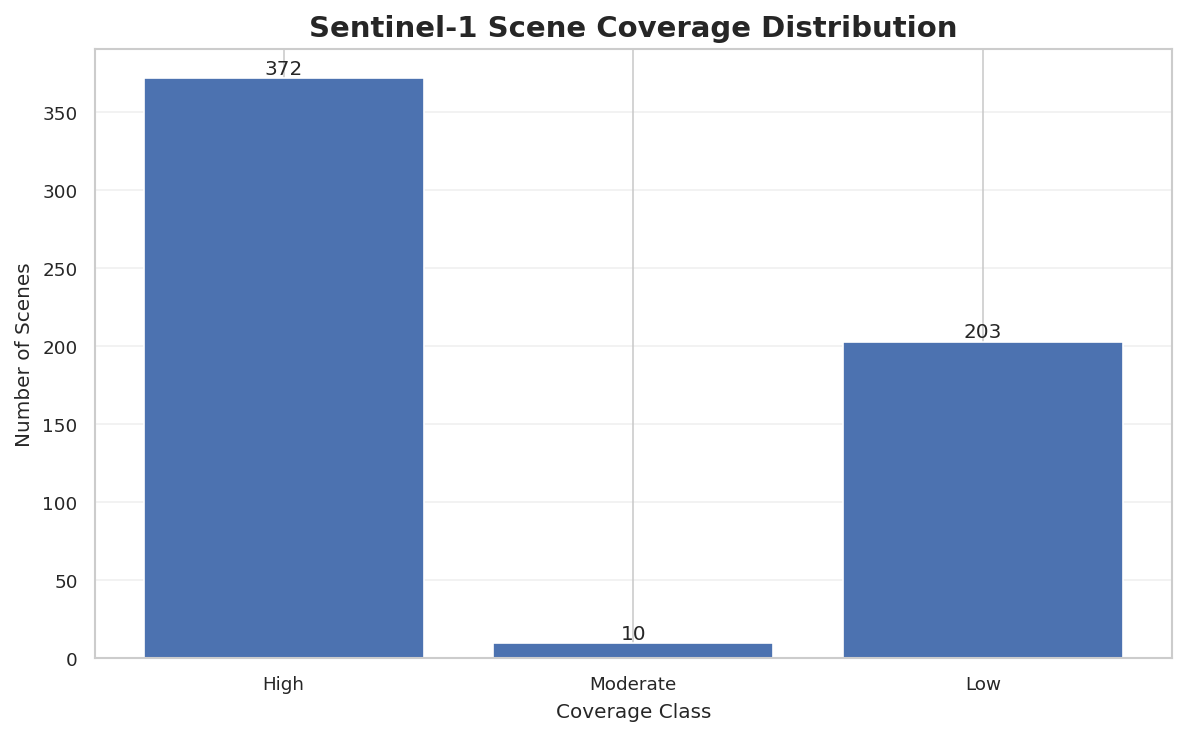

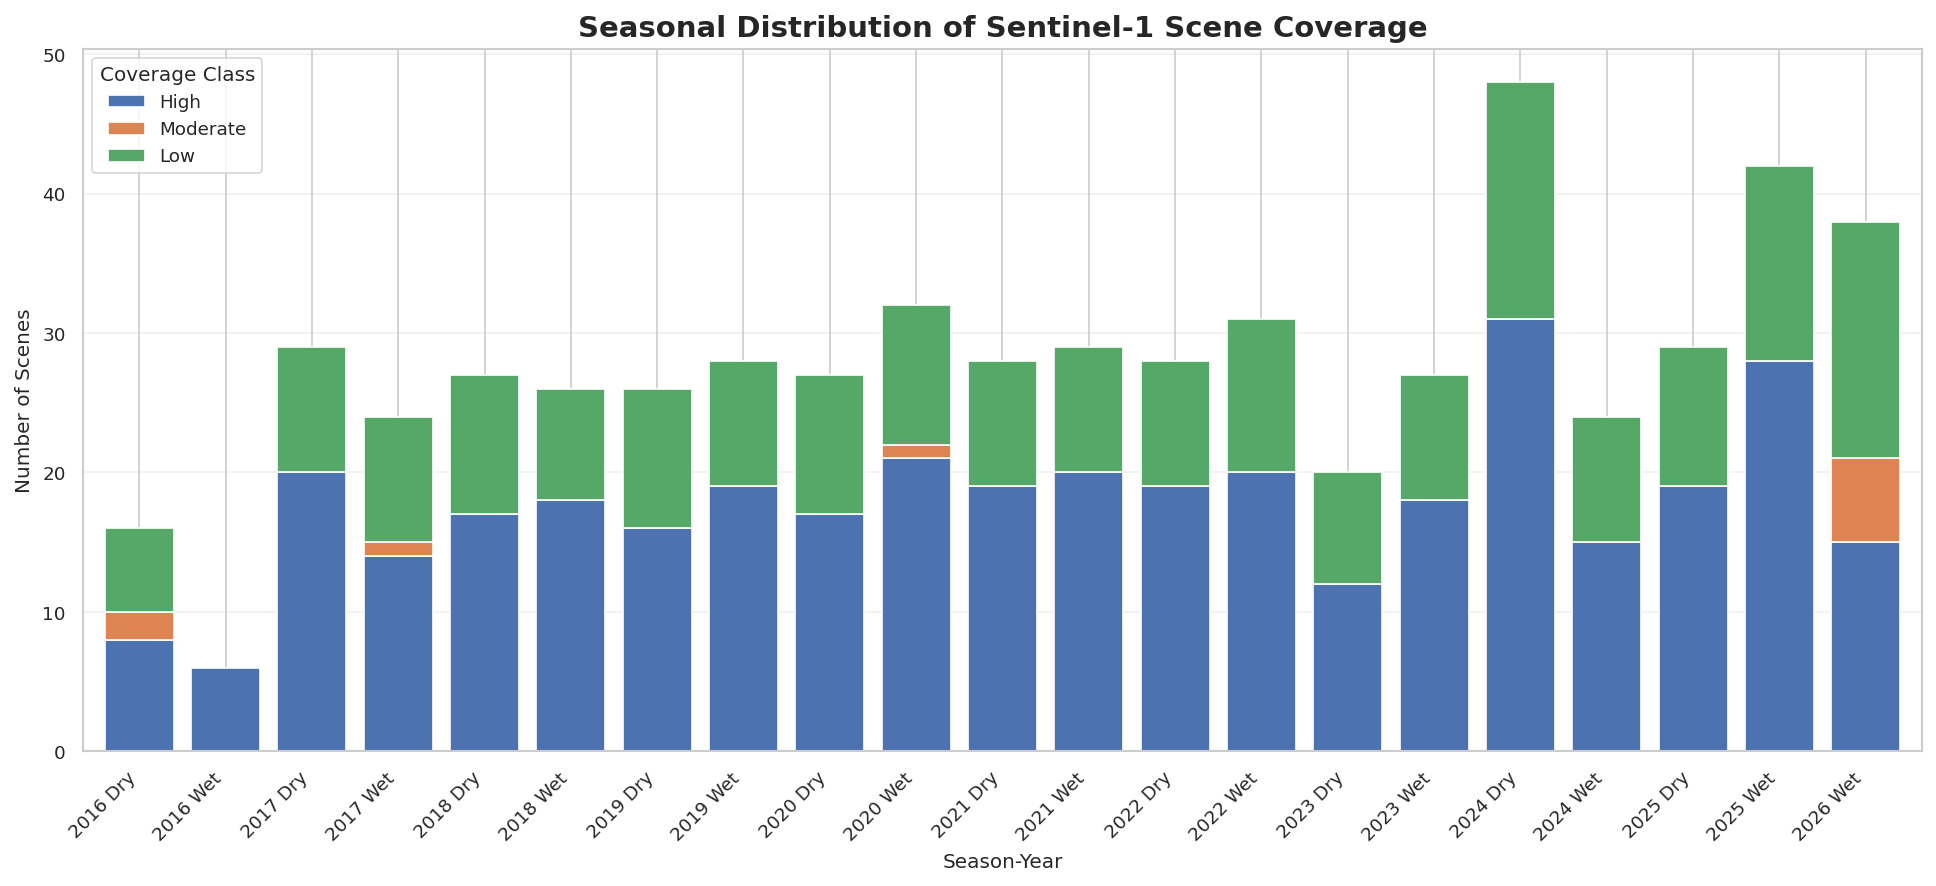

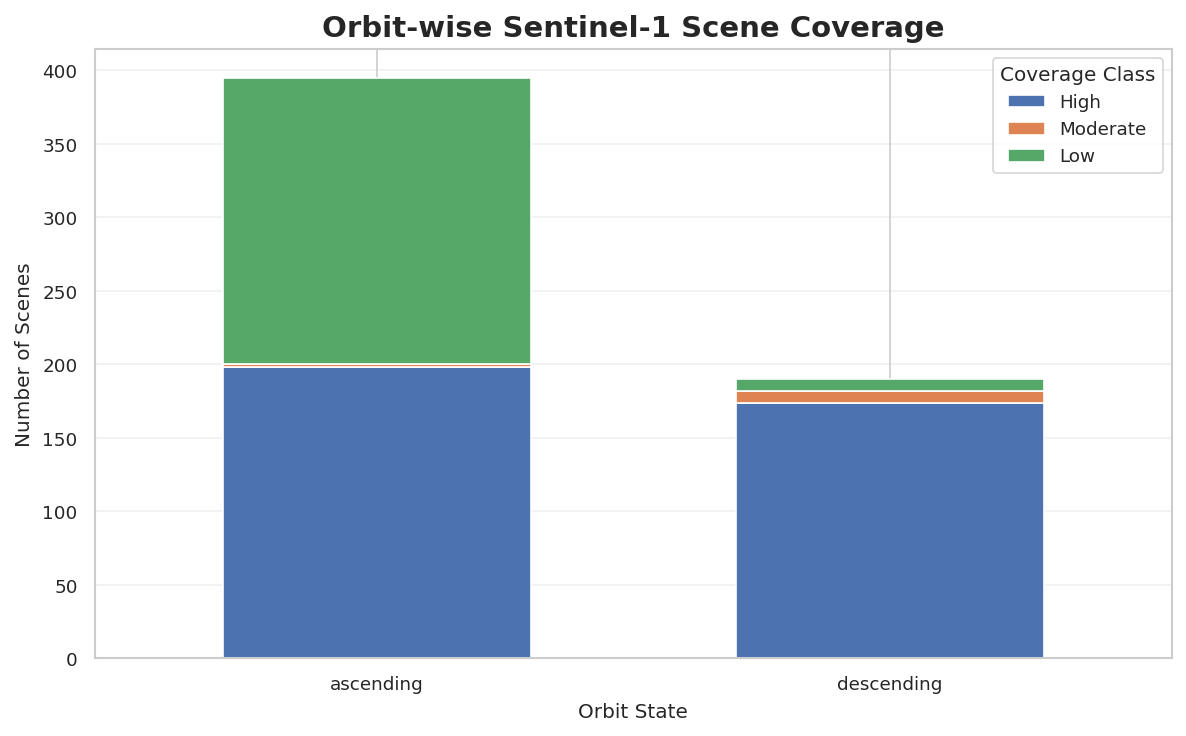


========== STEP 13 COMPLETED ==========
Total scenes classified: 585
CSV tables and 3 figures saved successfully.


In [ ]:
# ============================================================
# STEP 13: SENTINEL-1 SCENE COVERAGE CLASSIFICATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Output directories
results_dir = Path(
    "/content/Gopalganj_Wetland_Research/Results"
)
figures_dir = Path(
    "/content/Gopalganj_Wetland_Research/Figures"
)

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Copy data
coverage_df = footprints_utm.copy()

# 2. Classify coverage
def classify_coverage(value):
    if value >= 90:
        return "High"
    elif value >= 50:
        return "Moderate"
    else:
        return "Low"

coverage_df["Coverage_Class"] = (
    coverage_df["AOI_Coverage_Percent"]
    .apply(classify_coverage)
)

class_order = ["High", "Moderate", "Low"]

coverage_df["Coverage_Class"] = pd.Categorical(
    coverage_df["Coverage_Class"],
    categories=class_order,
    ordered=True
)

# ============================================================
# TABLE 1: OVERALL COVERAGE DISTRIBUTION
# ============================================================

overall_summary = (
    coverage_df["Coverage_Class"]
    .value_counts()
    .reindex(class_order, fill_value=0)
    .rename_axis("Coverage_Class")
    .reset_index(name="Scene_Count")
)

overall_summary["Percentage"] = (
    overall_summary["Scene_Count"]
    / len(coverage_df) * 100
)

print("\n========== OVERALL COVERAGE DISTRIBUTION ==========")
display(overall_summary.round(2))

# ============================================================
# TABLE 2: SEASON-YEAR COVERAGE DISTRIBUTION
# ============================================================

season_summary = (
    coverage_df
    .groupby(
        ["Season_Year", "Season_Type", "Coverage_Class"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=class_order, fill_value=0)
    .reset_index()
)

print("\n========== SEASON-YEAR COVERAGE ==========")
display(season_summary)

# ============================================================
# TABLE 3: ORBIT-WISE COVERAGE DISTRIBUTION
# ============================================================

orbit_summary = (
    coverage_df
    .groupby(
        ["Orbit_State", "Coverage_Class"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=class_order, fill_value=0)
    .reset_index()
)

print("\n========== ORBIT-WISE COVERAGE ==========")
display(orbit_summary)

# ============================================================
# GRAPH 1: OVERALL COVERAGE CLASS DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    overall_summary["Coverage_Class"].astype(str),
    overall_summary["Scene_Count"]
)

ax.set_title(
    "Sentinel-1 Scene Coverage Distribution",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Coverage Class")
ax.set_ylabel("Number of Scenes")
ax.grid(axis="y", alpha=0.3)

for bar, count in zip(
    bars, overall_summary["Scene_Count"]
):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{count}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    figures_dir / "Figure_13A_Overall_Coverage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# GRAPH 2: SEASON-YEAR COVERAGE DISTRIBUTION
# ============================================================

plot_df = coverage_df.copy()

plot_df["Season_Label"] = (
    plot_df["Season_Year"].astype(str)
    + " "
    + plot_df["Season_Type"].astype(str)
)

season_order = (
    plot_df[
        ["Season_Year", "Season_Type", "Season_Label"]
    ]
    .drop_duplicates()
    .sort_values(["Season_Year", "Season_Type"])
    ["Season_Label"]
    .tolist()
)

season_pivot = (
    plot_df
    .pivot_table(
        index="Season_Label",
        columns="Coverage_Class",
        values="Scene_ID",
        aggfunc="count",
        observed=False,
        fill_value=0
    )
    .reindex(
        index=season_order,
        columns=class_order,
        fill_value=0
    )
)

ax = season_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    width=0.8
)

ax.set_title(
    "Seasonal Distribution of Sentinel-1 Scene Coverage",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Season-Year")
ax.set_ylabel("Number of Scenes")
ax.legend(title="Coverage Class")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    figures_dir / "Figure_13B_Seasonal_Coverage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# GRAPH 3: ORBIT-WISE COVERAGE DISTRIBUTION
# ============================================================

orbit_pivot = (
    coverage_df
    .pivot_table(
        index="Orbit_State",
        columns="Coverage_Class",
        values="Scene_ID",
        aggfunc="count",
        observed=False,
        fill_value=0
    )
    .reindex(columns=class_order, fill_value=0)
)

ax = orbit_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    width=0.6
)

ax.set_title(
    "Orbit-wise Sentinel-1 Scene Coverage",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Orbit State")
ax.set_ylabel("Number of Scenes")
ax.legend(title="Coverage Class")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    figures_dir / "Figure_13C_Orbit_Coverage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# SAVE RESULTS
# ============================================================

coverage_df.drop(columns="Geometry").to_csv(
    results_dir / "Sentinel1_Coverage_Classified.csv",
    index=False
)

overall_summary.to_csv(
    results_dir / "Coverage_Overall_Summary.csv",
    index=False
)

season_summary.to_csv(
    results_dir / "Coverage_Seasonal_Summary.csv",
    index=False
)

orbit_summary.to_csv(
    results_dir / "Coverage_Orbit_Summary.csv",
    index=False
)

print("\n========== STEP 13 COMPLETED ==========")
print("Total scenes classified:", len(coverage_df))
print("CSV tables and 3 figures saved successfully.")


========== RELATIVE ORBIT COVERAGE ==========


Coverage_Class,Orbit_State,Relative_Orbit,High,Moderate,Low,Total_Scenes,High_Percent,Moderate_Percent,Low_Percent
0,ascending,12,0,0,191,191,0.00,0.00,100.00
1,ascending,114,198,2,4,204,97.06,0.98,1.96
2,ascending,150,0,0,0,0,NaN,NaN,NaN
3,descending,12,0,0,0,0,NaN,NaN,NaN
4,descending,114,0,0,0,0,NaN,NaN,NaN
5,descending,150,174,8,8,190,91.58,4.21,4.21



========== RELATIVE ORBIT STATISTICS ==========


,Orbit_State,Relative_Orbit,Scene_Count,Mean_Coverage,Median_Coverage,Minimum,Maximum,Standard_Deviation
0,ascending,12,191,2.80,0.35,0.27,7.08,3.09
1,ascending,114,204,98.04,100.00,0.56,100.00,12.26
2,descending,150,190,95.79,100.00,19.41,100.00,16.40


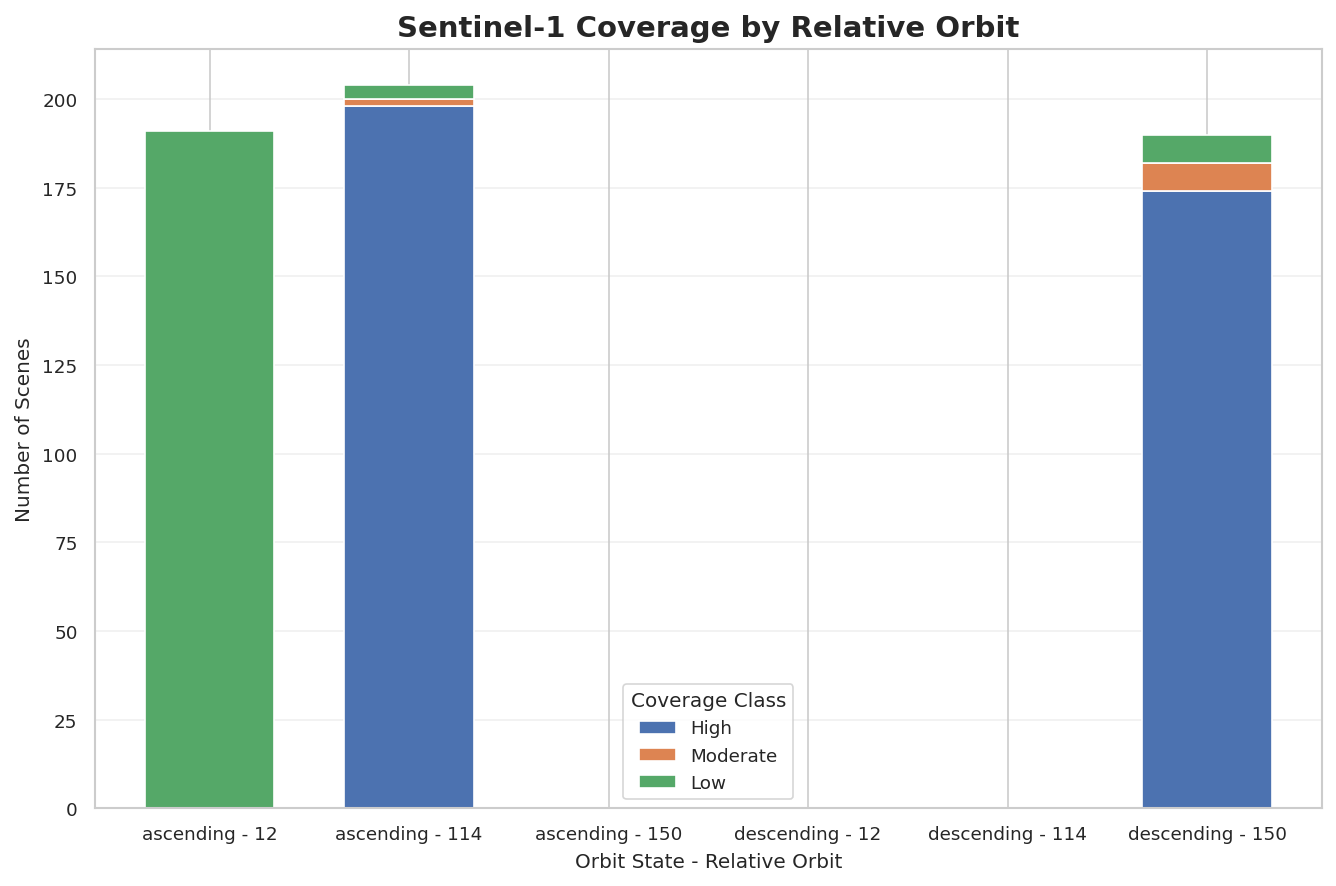

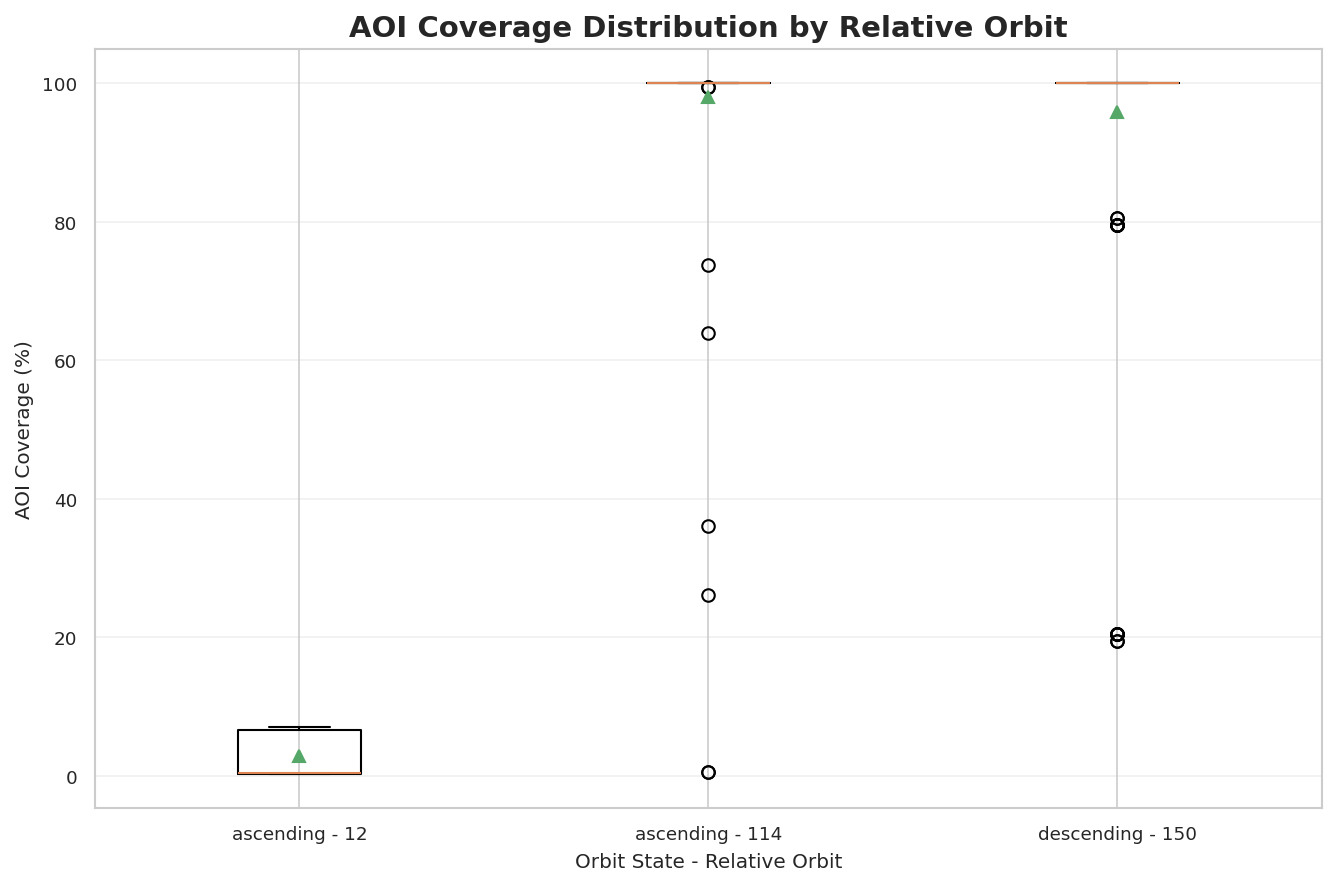


========== STEP 14A COMPLETED ==========
Relative orbit analysis completed successfully.


In [ ]:
# ============================================================
# STEP 14A: RELATIVE ORBIT-WISE COVERAGE ANALYSIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Use previously classified dataset
orbit_df = coverage_df.copy()

class_order = ["High", "Moderate", "Low"]

# ------------------------------------------------------------
# 1. RELATIVE ORBIT COVERAGE SUMMARY
# ------------------------------------------------------------

relative_orbit_summary = (
    orbit_df
    .groupby(
        ["Orbit_State", "Relative_Orbit", "Coverage_Class"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=class_order, fill_value=0)
    .reset_index()
)

relative_orbit_summary["Total_Scenes"] = (
    relative_orbit_summary[class_order].sum(axis=1)
)

for cls in class_order:
    relative_orbit_summary[cls + "_Percent"] = (
        relative_orbit_summary[cls]
        / relative_orbit_summary["Total_Scenes"] * 100
    )

print("\n========== RELATIVE ORBIT COVERAGE ==========")
display(relative_orbit_summary.round(2))


# ------------------------------------------------------------
# 2. RELATIVE ORBIT STATISTICS
# ------------------------------------------------------------

orbit_statistics = (
    orbit_df
    .groupby(
        ["Orbit_State", "Relative_Orbit"],
        observed=True
    )["AOI_Coverage_Percent"]
    .agg(
        Scene_Count="count",
        Mean_Coverage="mean",
        Median_Coverage="median",
        Minimum="min",
        Maximum="max",
        Standard_Deviation="std"
    )
    .reset_index()
)

print("\n========== RELATIVE ORBIT STATISTICS ==========")
display(orbit_statistics.round(2))


# ------------------------------------------------------------
# 3. GRAPH 1: RELATIVE ORBIT COVERAGE CLASS
# ------------------------------------------------------------

plot_df = relative_orbit_summary.copy()

plot_df["Orbit_Label"] = (
    plot_df["Orbit_State"].astype(str)
    + " - "
    + plot_df["Relative_Orbit"].astype(str)
)

plot_data = plot_df.set_index("Orbit_Label")[class_order]

ax = plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    width=0.65
)

ax.set_title(
    "Sentinel-1 Coverage by Relative Orbit",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Orbit State - Relative Orbit")
ax.set_ylabel("Number of Scenes")
ax.legend(title="Coverage Class")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "/content/Gopalganj_Wetland_Research/Figures/"
    "Figure_14A_Relative_Orbit_Coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 4. GRAPH 2: RELATIVE ORBIT COVERAGE BOXPLOT
# ------------------------------------------------------------

orbit_groups = []
orbit_labels = []

for (state, relative), group in orbit_df.groupby(
    ["Orbit_State", "Relative_Orbit"],
    observed=True
):
    orbit_groups.append(
        group["AOI_Coverage_Percent"].dropna().values
    )
    orbit_labels.append(f"{state} - {relative}")

fig, ax = plt.subplots(figsize=(9, 6))

ax.boxplot(
    orbit_groups,
    tick_labels=orbit_labels,
    showmeans=True
)

ax.set_title(
    "AOI Coverage Distribution by Relative Orbit",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Orbit State - Relative Orbit")
ax.set_ylabel("AOI Coverage (%)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/content/Gopalganj_Wetland_Research/Figures/"
    "Figure_14B_Relative_Orbit_Boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------------------

relative_orbit_summary.to_csv(
    "/content/Gopalganj_Wetland_Research/Results/"
    "Relative_Orbit_Coverage_Summary.csv",
    index=False
)

orbit_statistics.to_csv(
    "/content/Gopalganj_Wetland_Research/Results/"
    "Relative_Orbit_Coverage_Statistics.csv",
    index=False
)

print("\n========== STEP 14A COMPLETED ==========")
print("Relative orbit analysis completed successfully.")

In [ ]:
# ============================================================
# STEP 15A: INSTALL LIBRARIES AND CONNECT TO PLANETARY COMPUTER
# ============================================================

!pip -q install pystac-client planetary-computer stackstac \
    rioxarray rasterio geopandas shapely pyproj \
    matplotlib numpy pandas dask

import pystac_client
import planetary_computer as pc
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import stackstac
import rioxarray

# Connect to Planetary Computer
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace
)

print("Planetary Computer connection successful!")

# Check Sentinel-1 collection
collection = catalog.get_collection("sentinel-1-grd")

print("Collection:", collection.id)
print("Description:", collection.description[:300])

Planetary Computer connection successful!
Collection: sentinel-1-grd
Description: The [Sentinel-1](https://sentinel.esa.int/web/sentinel/missions/sentinel-1) mission is a constellation of two polar-orbiting satellites, operating day and night performing C-band synthetic aperture radar imaging. The Level-1 Ground Range Detected (GRD) products in this Collection consist of focused 


In [ ]:
# ============================================================
# STEP 15B: INSPECT SENTINEL-1 VV/VH RASTER ASSETS
# ============================================================

# Select one scene from each selected relative orbit
sample_scenes = (
    s1_usable[
        (
            (s1_usable["Orbit_State"] == "ascending") &
            (s1_usable["Relative_Orbit"] == 114)
        ) |
        (
            (s1_usable["Orbit_State"] == "descending") &
            (s1_usable["Relative_Orbit"] == 150)
        )
    ]
    .groupby(["Orbit_State", "Relative_Orbit"])
    .first()
    .reset_index()
)

for _, row in sample_scenes.iterrows():

    scene_id = row["Scene_ID"]

    print("\n" + "=" * 60)
    print("Orbit:", row["Orbit_State"])
    print("Relative Orbit:", row["Relative_Orbit"])
    print("Scene ID:", scene_id)

    search = catalog.search(
        collections=["sentinel-1-grd"],
        ids=[scene_id]
    )

    items = list(search.items())

    if not items:
        print("Scene not found!")
        continue

    item = items[0]

    print("\nAvailable raster assets:")

    for key, asset in item.assets.items():
        print(
            "Asset:", key,
            "| Media type:", asset.media_type,
            "| Roles:", asset.roles
        )


Orbit: ascending
Relative Orbit: 114
Scene ID: S1A_IW_GRDH_1SDV_20160604T120402_20160604T120425_011561_011A73

Available raster assets:
Asset: vh | Media type: image/tiff; application=geotiff; profile=cloud-optimized | Roles: ['data']
Asset: vv | Media type: image/tiff; application=geotiff; profile=cloud-optimized | Roles: ['data']
Asset: thumbnail | Media type: image/png | Roles: ['thumbnail']
Asset: safe-manifest | Media type: application/xml | Roles: ['metadata']
Asset: schema-noise-vh | Media type: application/xml | Roles: ['metadata']
Asset: schema-noise-vv | Media type: application/xml | Roles: ['metadata']
Asset: schema-product-vh | Media type: application/xml | Roles: ['metadata']
Asset: schema-product-vv | Media type: application/xml | Roles: ['metadata']
Asset: schema-calibration-vh | Media type: application/xml | Roles: ['metadata']
Asset: schema-calibration-vv | Media type: application/xml | Roles: ['metadata']
Asset: tilejson | Media type: application/json | Roles: ['tile

In [58]:
# ============================================================
# STEP 15C: CHECK SENTINEL-1 GCP GEOREFERENCING
# ============================================================

import rasterio
from rasterio.transform import GCPTransformer
from rasterio.warp import transform_bounds
import geopandas as gpd
import planetary_computer as pc

# Load AOI
aoi = gpd.read_file(
    "/content/Gopalganj_Wetland_Research/Data/Gopalganj_Boundary.geojson"
)

# Select Ascending 114 scene
scene_id = sample_scenes.loc[
    (sample_scenes["Orbit_State"] == "ascending") &
    (sample_scenes["Relative_Orbit"] == 114),
    "Scene_ID"
].iloc[0]

item = list(catalog.search(
    collections=["sentinel-1-grd"],
    ids=[scene_id]
).items())[0]

item = pc.sign(item)

# Inspect VV raster
with rasterio.open(item.assets["vv"].href) as src:

    gcps, gcp_crs = src.gcps

    print("Raster dimensions:", src.width, src.height)
    print("Raster CRS:", src.crs)
    print("GCP CRS:", gcp_crs)
    print("Number of GCPs:", len(gcps))
    print("Raster bounds:", src.bounds)
    print("AOI bounds:", aoi.total_bounds)

    # Transform AOI bounds into raster coordinate system
    aoi_bounds = transform_bounds(
        aoi.crs,
        gcp_crs,
        *aoi.total_bounds
    )

    print("\nAOI bounds in raster CRS:", aoi_bounds)

    # Transform sample GCP pixel/line coordinates
    with GCPTransformer(gcps) as transformer:
        print(
            "Sample GCP pixel-to-world:",
            transformer.xy(0, 0)
        )

Raster dimensions: 25192 15316
Raster CRS: None
GCP CRS: EPSG:4326
Number of GCPs: 189
Raster bounds: BoundingBox(left=0.0, bottom=15316.0, right=25192.0, top=0.0)
AOI bounds: [89.6725664  22.85292896 90.14377326 23.36054376]

AOI bounds in raster CRS: (89.67256640100004, 22.852928957000074, 90.14377326400006, 23.36054376000004)
Sample GCP pixel-to-world: (np.float64(89.40320702311185), np.float64(22.386632029954185))


In [60]:
# ============================================================
# STEP 15C: GCP PIXEL COORDINATE TEST
# ============================================================

import rasterio
import geopandas as gpd
import planetary_computer as pc
from rasterio.transform import GCPTransformer

# Load AOI
aoi = gpd.read_file(
    "/content/Gopalganj_Wetland_Research/Data/Gopalganj_Boundary.geojson"
).to_crs("EPSG:4326")

# Retrieve scene
scene_id = sample_scenes.loc[
    (sample_scenes["Orbit_State"] == "ascending") &
    (sample_scenes["Relative_Orbit"] == 114),
    "Scene_ID"
].iloc[0]

item = list(catalog.search(
    collections=["sentinel-1-grd"],
    ids=[scene_id]
).items())[0]

item = pc.sign(item)

# Test VV GCP transformation
with rasterio.open(item.assets["vv"].href) as src:

    gcps, gcp_crs = src.gcps

    with GCPTransformer(gcps) as transformer:

        # AOI corner coordinates
        minx, miny, maxx, maxy = aoi.total_bounds

        test_points = [
            (minx, miny),
            (minx, maxy),
            (maxx, miny),
            (maxx, maxy)
        ]

        for lon, lat in test_points:

            row, col = transformer.rowcol(
                lon, lat,
                op=lambda x: round(x)
            )

            print(
                f"Longitude: {lon:.5f}, Latitude: {lat:.5f}",
                f"=> Row: {row}, Col: {col}"
            )

Longitude: 89.67257, Latitude: 22.85293 => Row: 4470, Col: 3711
Longitude: 89.67257, Latitude: 23.36054 => Row: 9907, Col: 4782
Longitude: 90.14377, Latitude: 22.85293 => Row: 3575, Col: 8460
Longitude: 90.14377, Latitude: 23.36054 => Row: 9020, Col: 9514



Processing VV...
Output shape: (5627, 4813)
Valid pixels: 14784271
Minimum: 11.0
Maximum: 12772.0
Saved: /content/Gopalganj_Wetland_Research/Results/Sentinel1_Test/Gopalganj_VV_Test.tif

Processing VH...
Output shape: (5627, 4813)
Valid pixels: 14784271
Minimum: 7.0
Maximum: 4702.0
Saved: /content/Gopalganj_Wetland_Research/Results/Sentinel1_Test/Gopalganj_VH_Test.tif


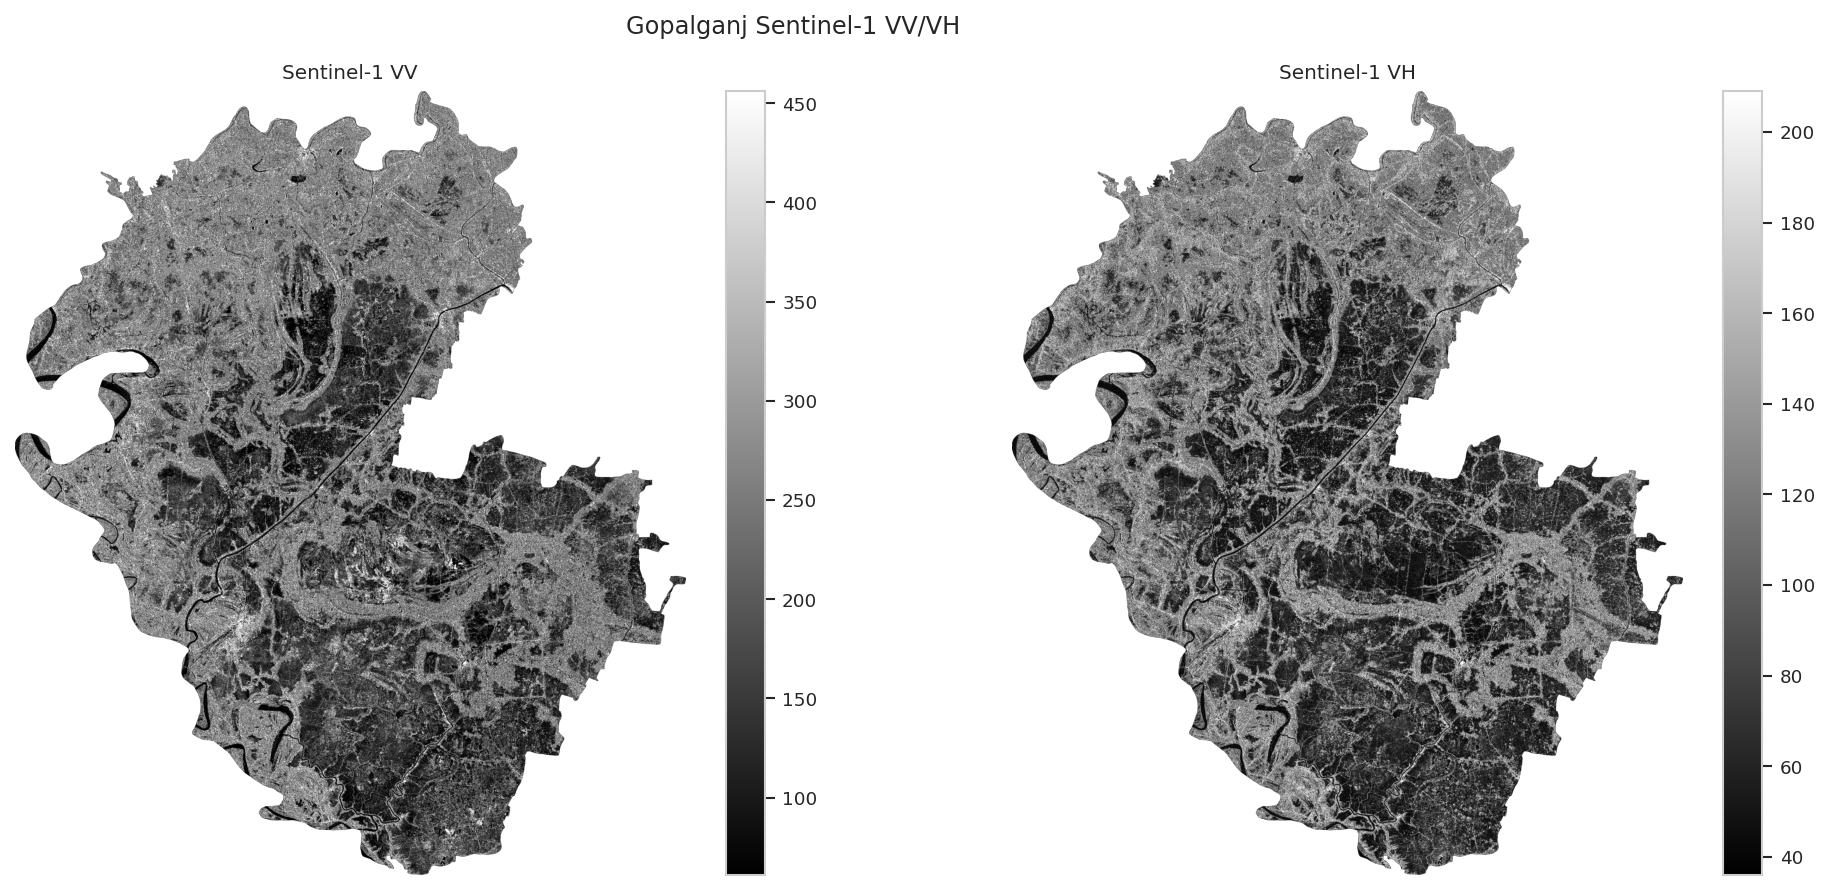

In [61]:
# ============================================================
# STEP 15C: GCP-BASED SENTINEL-1 REPROJECTION AND CLIPPING
# ============================================================

import os
import rasterio
import geopandas as gpd
import planetary_computer as pc
import numpy as np
import matplotlib.pyplot as plt

from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from rasterio.features import geometry_mask

# 1. Load AOI
aoi = gpd.read_file(
    "/content/Gopalganj_Wetland_Research/Data/Gopalganj_Boundary.geojson"
)

# UTM Zone 46N
target_crs = "EPSG:32646"
aoi_utm = aoi.to_crs(target_crs)

# 2. Retrieve sample scene
scene_id = sample_scenes.loc[
    (sample_scenes["Orbit_State"] == "ascending") &
    (sample_scenes["Relative_Orbit"] == 114),
    "Scene_ID"
].iloc[0]

item = list(catalog.search(
    collections=["sentinel-1-grd"],
    ids=[scene_id]
).items())[0]

item = pc.sign(item)

# 3. Define output grid
resolution = 10

minx, miny, maxx, maxy = aoi_utm.total_bounds

width = int(np.ceil((maxx - minx) / resolution))
height = int(np.ceil((maxy - miny) / resolution))

dst_transform = from_origin(
    minx, maxy, resolution, resolution
)

# 4. Create exact AOI mask
inside_aoi = geometry_mask(
    aoi_utm.geometry,
    out_shape=(height, width),
    transform=dst_transform,
    invert=True
)

# Output folder
output_dir = (
    "/content/Gopalganj_Wetland_Research/Results/"
    "Sentinel1_Test"
)

os.makedirs(output_dir, exist_ok=True)

clipped_bands = {}

# 5. Reproject using GCPs
for band in ["vv", "vh"]:

    print(f"\nProcessing {band.upper()}...")

    with rasterio.open(item.assets[band].href) as src:

        gcps, gcp_crs = src.gcps

        destination = np.full(
            (height, width),
            np.nan,
            dtype="float32"
        )

        warp_options = {}

        if src.nodata is not None:
            warp_options["src_nodata"] = src.nodata

        reproject(
            source=rasterio.band(src, 1),
            destination=destination,
            gcps=gcps,
            src_crs=gcp_crs,
            dst_transform=dst_transform,
            dst_crs=target_crs,
            dst_nodata=np.nan,
            resampling=Resampling.nearest,
            **warp_options
        )

        # Apply exact AOI boundary
        destination[~inside_aoi] = np.nan

        clipped_bands[band] = destination

        # Save GeoTIFF
        output_path = os.path.join(
            output_dir,
            f"Gopalganj_{band.upper()}_Test.tif"
        )

        with rasterio.open(
            output_path,
            "w",
            driver="GTiff",
            height=height,
            width=width,
            count=1,
            dtype="float32",
            crs=target_crs,
            transform=dst_transform,
            nodata=np.nan,
            compress="deflate"
        ) as dst:

            dst.write(destination, 1)

        valid = np.isfinite(destination)

        print("Output shape:", destination.shape)
        print("Valid pixels:", valid.sum())
        print("Minimum:", np.nanmin(destination))
        print("Maximum:", np.nanmax(destination))
        print("Saved:", output_path)

# 6. Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, band in zip(axes, ["vv", "vh"]):

    data = clipped_bands[band]

    vmin, vmax = np.nanpercentile(data, [2, 98])

    im = ax.imshow(
        data,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(f"Sentinel-1 {band.upper()}")
    ax.axis("off")

    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Gopalganj Sentinel-1 VV/VH")
plt.tight_layout()
plt.show()

In [62]:
# ============================================================
# STEP 15D: SENTINEL-1 RADIOMETRIC METADATA CHECK
# ============================================================

import rasterio
import numpy as np

for band in ["vv", "vh"]:

    print("\n" + "=" * 55)
    print("BAND:", band.upper())

    with rasterio.open(item.assets[band].href) as src:

        print("Data type:", src.dtypes)
        print("NoData:", src.nodata)
        print("Scale:", src.scales)
        print("Offset:", src.offsets)
        print("Raster tags:", src.tags())

    # Check saved clipped raster
    path = (
        f"/content/Gopalganj_Wetland_Research/Results/"
        f"Sentinel1_Test/Gopalganj_{band.upper()}_Test.tif"
    )

    with rasterio.open(path) as src:

        data = src.read(1)
        valid = data[np.isfinite(data)]

        print("\nClipped raster statistics:")
        print("Percentiles:", np.percentile(
            valid, [0, 1, 5, 25, 50, 75, 95, 99, 100]
        ))


BAND: VV
Data type: ('uint16',)
NoData: 0.0
Scale: (1.0,)
Offset: (0.0,)
Raster tags: {'TIFFTAG_IMAGEDESCRIPTION': 'Sentinel-1A IW GRD HR L1', 'TIFFTAG_SOFTWARE': 'Sentinel-1 IPF 002.71', 'TIFFTAG_DATETIME': '2016:06:04 18:12:48', 'AREA_OR_POINT': 'Area'}

Clipped raster statistics:
Percentiles: [1.1000e+01 5.3000e+01 7.7000e+01 1.4600e+02 2.1400e+02 2.8200e+02
 3.9100e+02 5.2000e+02 1.2772e+04]

BAND: VH
Data type: ('uint16',)
NoData: 0.0
Scale: (1.0,)
Offset: (0.0,)
Raster tags: {'TIFFTAG_IMAGEDESCRIPTION': 'Sentinel-1A IW GRD HR L1', 'TIFFTAG_SOFTWARE': 'Sentinel-1 IPF 002.71', 'TIFFTAG_DATETIME': '2016:06:04 18:13:34', 'AREA_OR_POINT': 'Area'}

Clipped raster statistics:
Percentiles: [   7.   32.   42.   67.   99.  133.  183.  229. 4702.]


In [63]:
# ============================================================
# STEP 15E: CHECK SENTINEL-1 RTC AVAILABILITY
# ============================================================

import planetary_computer as pc
import pystac_client
import geopandas as gpd

# Load AOI
aoi = gpd.read_file(
    "/content/Gopalganj_Wetland_Research/Data/Gopalganj_Boundary.geojson"
)

# Connect to catalog
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace
)

# Check RTC collection
rtc_collection = catalog.get_collection("sentinel-1-rtc")

print("RTC Collection:", rtc_collection.id)
print("Description:", rtc_collection.description[:300])

# Search near sample acquisition date
items = catalog.search(
    collections=["sentinel-1-rtc"],
    bbox=list(aoi.to_crs("EPSG:4326").total_bounds),
    datetime="2016-06-03/2016-06-06",
    max_items=100
).item_collection()

print("\nRTC scenes found:", len(items))

for item in items[:10]:

    print("\nScene ID:", item.id)
    print("Date:", item.datetime)
    print("Orbit State:", item.properties.get("sat:orbit_state"))
    print("Relative Orbit:", item.properties.get("sat:relative_orbit"))
    print("Assets:", list(item.assets.keys()))

RTC Collection: sentinel-1-rtc
Description: The [Sentinel-1](https://sentinel.esa.int/web/sentinel/missions/sentinel-1) mission is a constellation of two polar-orbiting satellites, operating day and night performing C-band synthetic aperture radar imaging. The Sentinel-1 Radiometrically Terrain Corrected (RTC) data in this collection is a rad

RTC scenes found: 2

Scene ID: S1A_IW_GRDH_1SDV_20160606T235552_20160606T235617_011597_011B95_rtc
Date: 2016-06-06 23:56:04.626886+00:00
Orbit State: descending
Relative Orbit: 150
Assets: ['vh', 'vv', 'tilejson', 'rendered_preview']

Scene ID: S1A_IW_GRDH_1SDV_20160604T120402_20160604T120425_011561_011A73_rtc
Date: 2016-06-04 12:04:13.714303+00:00
Orbit State: ascending
Relative Orbit: 114
Assets: ['vh', 'vv', 'tilejson', 'rendered_preview']



Processing: VV
CRS: EPSG:32646
Resolution: (10.0, 10.0)
Data type: ('float32',)
NoData: -32768.0
Bounds: BoundingBox(left=103310.0, bottom=2480040.0, right=377940.0, top=2675050.0)
Shape: (5627, 4814)
Valid pixels: 14784151
Minimum dB: -30.30216
Maximum dB: 27.047031
Median dB: -8.235168
Saved: /content/Gopalganj_Wetland_Research/Results/Sentinel1_RTC_Test/Gopalganj_RTC_VV_dB.tif

Processing: VH
CRS: EPSG:32646
Resolution: (10.0, 10.0)
Data type: ('float32',)
NoData: -32768.0
Bounds: BoundingBox(left=103310.0, bottom=2480040.0, right=377940.0, top=2675050.0)
Shape: (5627, 4814)
Valid pixels: 14784151
Minimum dB: -31.349323
Maximum dB: 16.962593
Median dB: -14.882393
Saved: /content/Gopalganj_Wetland_Research/Results/Sentinel1_RTC_Test/Gopalganj_RTC_VH_dB.tif


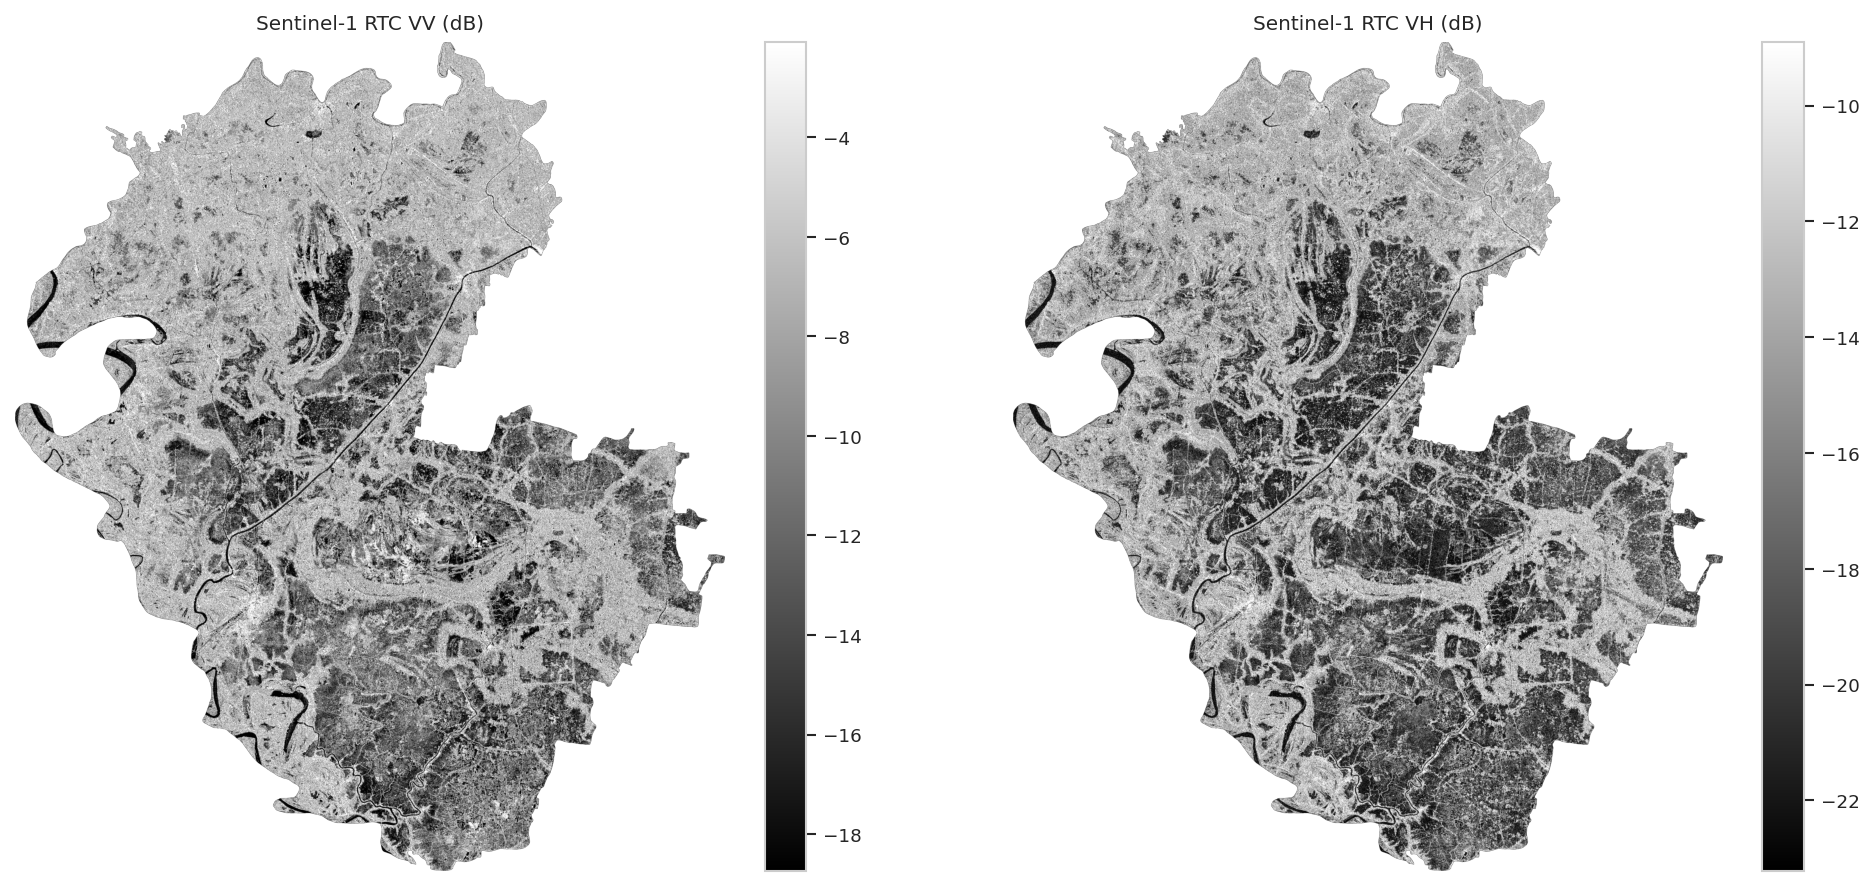

In [64]:
# ============================================================
# STEP 15F: SENTINEL-1 RTC VV/VH PROCESSING
# ============================================================

import os
import numpy as np
import rasterio
import geopandas as gpd
import planetary_computer as pc
import matplotlib.pyplot as plt

from rasterio.mask import mask
from shapely.geometry import mapping

# 1. Load AOI
aoi = gpd.read_file(
    "/content/Gopalganj_Wetland_Research/Data/Gopalganj_Boundary.geojson"
)

# 2. Find exact RTC scene
rtc_id = (
    "S1A_IW_GRDH_1SDV_20160604T120402_"
    "20160604T120425_011561_011A73_rtc"
)

rtc_item = list(catalog.search(
    collections=["sentinel-1-rtc"],
    ids=[rtc_id]
).items())[0]

rtc_item = pc.sign(rtc_item)

# 3. Output directory
output_dir = (
    "/content/Gopalganj_Wetland_Research/Results/"
    "Sentinel1_RTC_Test"
)

os.makedirs(output_dir, exist_ok=True)

rtc_db = {}

# 4. Process VV and VH
for band in ["vv", "vh"]:

    print("\nProcessing:", band.upper())

    with rasterio.open(rtc_item.assets[band].href) as src:

        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Data type:", src.dtypes)
        print("NoData:", src.nodata)
        print("Bounds:", src.bounds)

        # Reproject AOI to raster CRS
        aoi_projected = aoi.to_crs(src.crs)

        # Read and clip only AOI
        clipped, transform = mask(
            src,
            [mapping(g) for g in aoi_projected.geometry],
            crop=True,
            filled=False
        )

        # Convert to float
        linear = clipped[0].astype("float32").filled(np.nan)

        # Remove invalid and NoData pixels
        linear[~np.isfinite(linear)] = np.nan
        linear[linear <= 0] = np.nan

        # Convert linear power to dB
        db = 10 * np.log10(linear)

        rtc_db[band] = db

        # Save dB raster
        output_path = os.path.join(
            output_dir,
            f"Gopalganj_RTC_{band.upper()}_dB.tif"
        )

        profile = {
            "driver": "GTiff",
            "height": db.shape[0],
            "width": db.shape[1],
            "count": 1,
            "dtype": "float32",
            "crs": src.crs,
            "transform": transform,
            "nodata": np.nan,
            "compress": "deflate"
        }

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(db, 1)

        print("Shape:", db.shape)
        print("Valid pixels:", np.isfinite(db).sum())
        print("Minimum dB:", np.nanmin(db))
        print("Maximum dB:", np.nanmax(db))
        print("Median dB:", np.nanmedian(db))
        print("Saved:", output_path)

# 5. Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, band in zip(axes, ["vv", "vh"]):

    data = rtc_db[band]

    im = ax.imshow(
        data,
        cmap="gray",
        vmin=np.nanpercentile(data, 2),
        vmax=np.nanpercentile(data, 98)
    )

    ax.set_title(f"Sentinel-1 RTC {band.upper()} (dB)")
    ax.axis("off")

    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

RTC Scene: S1A_IW_GRDH_1SDV_20160604T120402_20160604T120425_011561_011A73_rtc

Processing: VV
CRS: EPSG:32646
Resolution: (10.0, 10.0)
Data type: ('float32',)
NoData: -32768.0
Bounds: BoundingBox(left=103310.0, bottom=2480040.0, right=377940.0, top=2675050.0)

--- VV STATISTICS ---
Valid pixels: 14784151
Minimum: -30.30216
Maximum: 27.047031
Mean: -8.935969
Median: -8.235168
Percentiles: [-19.87414074 -16.77935314 -11.39281321  -8.23516846  -6.0541327
  -3.39150131  -0.91762263]
Saved: /content/Gopalganj_Wetland_Research/Results/Sentinel1_RTC_Test/Gopalganj_RTC_VV_dB.tif

Processing: VH
CRS: EPSG:32646
Resolution: (10.0, 10.0)
Data type: ('float32',)
NoData: -32768.0
Bounds: BoundingBox(left=103310.0, bottom=2480040.0, right=377940.0, top=2675050.0)

--- VH STATISTICS ---
Valid pixels: 14784151
Minimum: -31.349323
Maximum: 16.962593
Mean: -15.428404
Median: -14.882393
Percentiles: [-23.96460152 -22.03246403 -18.29469872 -14.88239288 -12.55409145
  -9.96482086  -8.13114643]
Saved: /cont

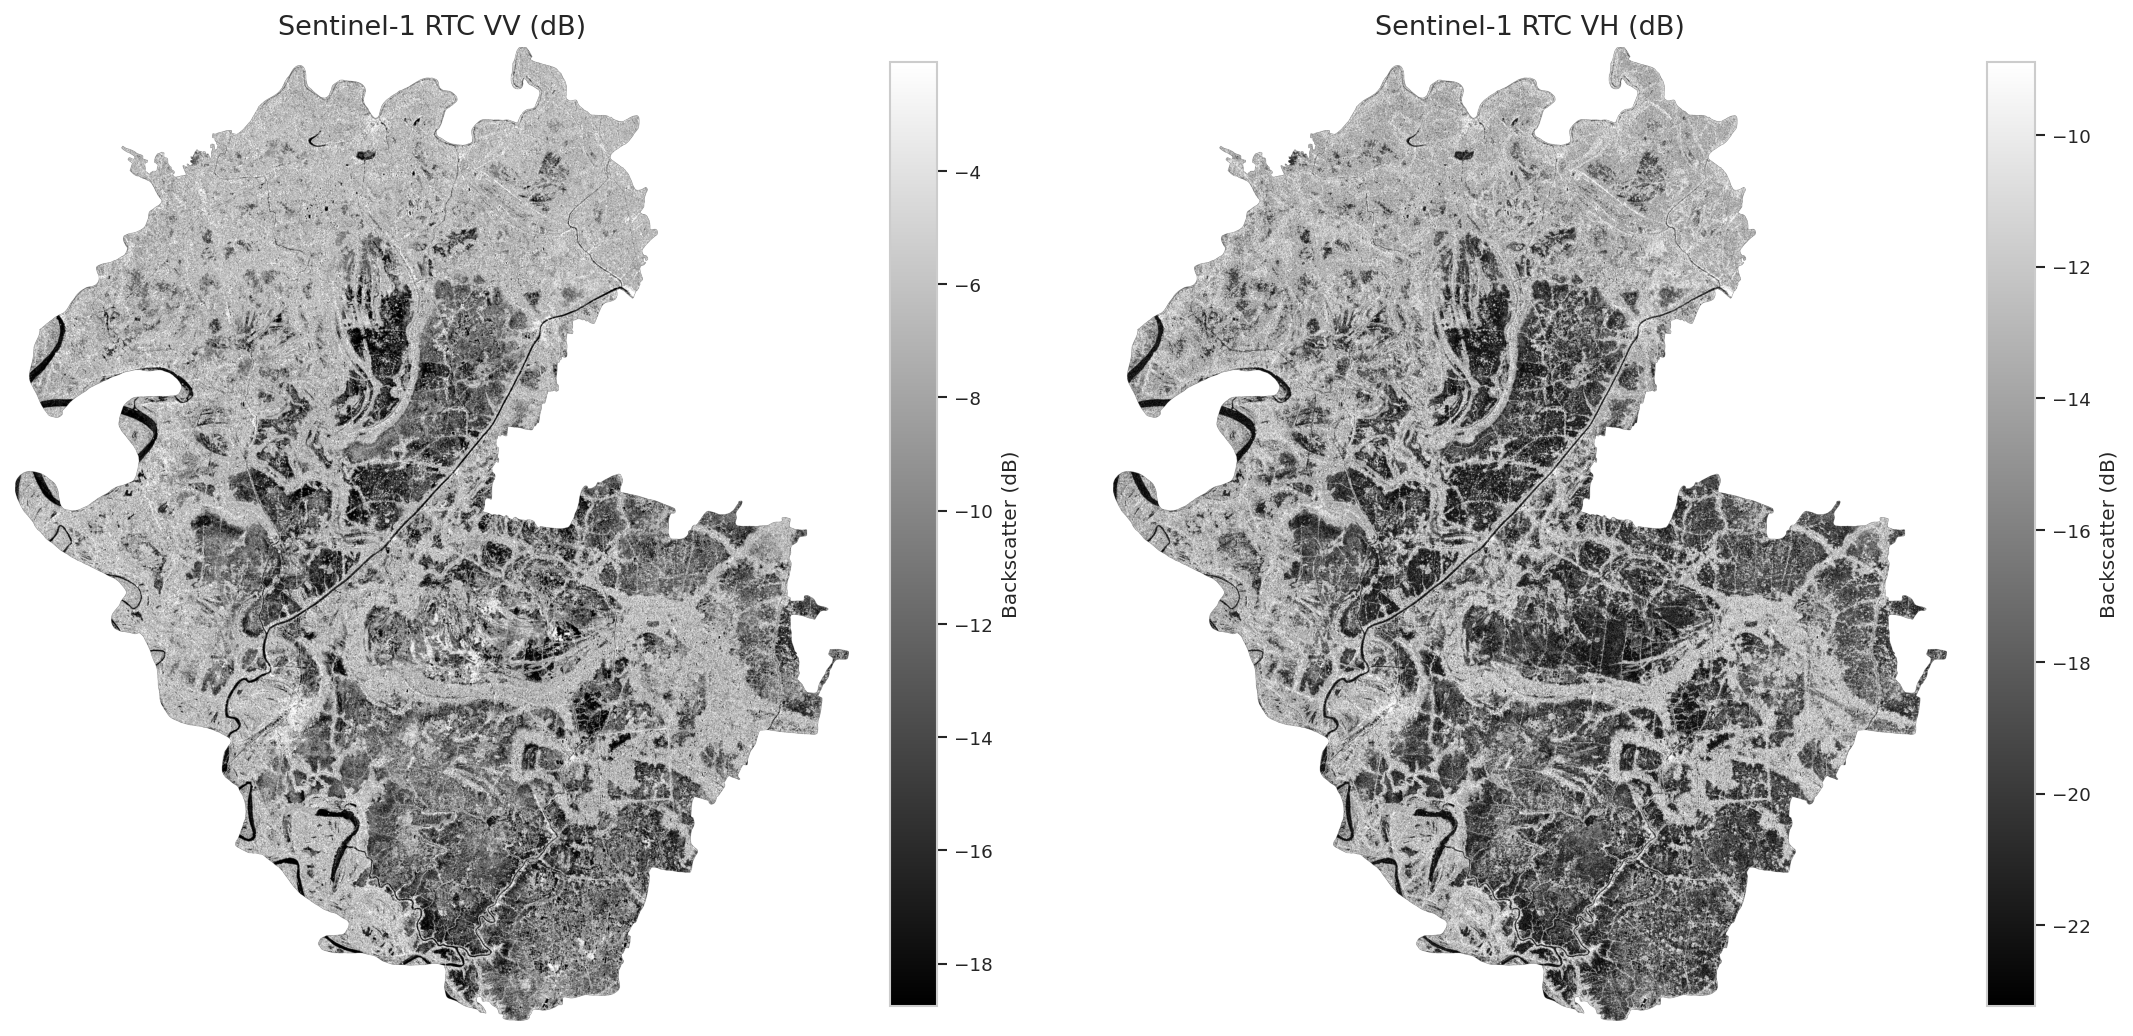


Preview saved: /content/Gopalganj_Wetland_Research/Results/Sentinel1_RTC_Test/RTC_VV_VH_Preview.png

VV and VH processing completed.


In [65]:
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from rasterio.mask import mask
from shapely.geometry import mapping
from IPython.display import display

# --------------------------------------------------
# 1. Output directory
# --------------------------------------------------

output_dir = (
    "/content/Gopalganj_Wetland_Research/"
    "Results/Sentinel1_RTC_Test"
)

os.makedirs(output_dir, exist_ok=True)

# --------------------------------------------------
# 2. Retrieve RTC scene
# --------------------------------------------------

rtc_id = (
    "S1A_IW_GRDH_1SDV_20160604T120402_"
    "20160604T120425_011561_011A73_rtc"
)

rtc_item = next(
    catalog.search(
        collections=["sentinel-1-rtc"],
        ids=[rtc_id]
    ).items()
)

print("RTC Scene:", rtc_item.id)

# --------------------------------------------------
# 3. Process VV and VH
# --------------------------------------------------

results = {}

for band in ["vv", "vh"]:

    print("\n" + "=" * 55)
    print("Processing:", band.upper())
    print("=" * 55)

    asset_url = rtc_item.assets[band].href

    with rasterio.open(asset_url) as src:

        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Data type:", src.dtypes)
        print("NoData:", src.nodata)
        print("Bounds:", src.bounds)

        # Reproject AOI to raster CRS
        aoi_projected = aoi.to_crs(src.crs)

        # Clip raster
        clipped, transform = mask(
            src,
            [mapping(g) for g in aoi_projected.geometry],
            crop=True,
            filled=False
        )

        # Convert to float32
        linear = clipped[0].astype(
            "float32"
        ).filled(np.nan)

        # Remove invalid and zero values
        linear[
            (~np.isfinite(linear)) |
            (linear <= 0)
        ] = np.nan

        # Convert linear power to dB
        db = 10 * np.log10(linear)

        # Statistics
        valid = db[np.isfinite(db)]

        print("\n---", band.upper(), "STATISTICS ---")
        print("Valid pixels:", len(valid))
        print("Minimum:", np.nanmin(db))
        print("Maximum:", np.nanmax(db))
        print("Mean:", np.nanmean(db))
        print("Median:", np.nanmedian(db))

        print(
            "Percentiles:",
            np.nanpercentile(
                valid,
                [1, 5, 25, 50, 75, 95, 99]
            )
        )

        # Save GeoTIFF
        output_file = os.path.join(
            output_dir,
            f"Gopalganj_RTC_{band.upper()}_dB.tif"
        )

        profile = {
            "driver": "GTiff",
            "height": db.shape[0],
            "width": db.shape[1],
            "count": 1,
            "dtype": "float32",
            "crs": src.crs,
            "transform": transform,
            "nodata": -9999.0,
            "compress": "deflate"
        }

        output_array = np.where(
            np.isfinite(db),
            db,
            -9999.0
        ).astype("float32")

        with rasterio.open(
            output_file,
            "w",
            **profile
        ) as dst:

            dst.write(output_array, 1)

        print("Saved:", output_file)

        results[band] = db

# --------------------------------------------------
# 4. Preview VV and VH
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 7)
)

for ax, band in zip(axes, ["vv", "vh"]):

    image = results[band]

    vmin, vmax = np.nanpercentile(
        image,
        [2, 98]
    )

    im = ax.imshow(
        image,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(
        f"Sentinel-1 RTC {band.upper()} (dB)",
        fontsize=13
    )

    ax.axis("off")

    plt.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label="Backscatter (dB)"
    )

plt.tight_layout()

figure_path = os.path.join(
    output_dir,
    "RTC_VV_VH_Preview.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nPreview saved:", figure_path)
print("\nVV and VH processing completed.")